# Árvore de Decisão

Árvore de Decisão é uma técnica simples de classificador, bastante útil quando as relações que definem a classe da variável resposta são não-lineares ou quando é importante para a classificação interações entre as variáveis independentes (_features_).

A árvore é composta de três tipos de nós (vértices):

* **raiz**: um nó sem anteriores, ligado a nenhum ou mais (normalmente 2, no nosso caso) nós;
* **nó interno**: nó que não é raiz nem folha; possui só um nó anterior e 2 (ou mais) nós seguintes;
* **folha**: nó que não possui nós seguintes; é o resultado da classificação.

Todo nó não-folha contém um teste de condição sobre (geralmente) um atributo. O resultado desse teste tem uma saída para cada resultado do teste. Uma vez atingido uma folha, uma classe é atribuída a ela. Exemplos podem ser observados a seguir, para determinar (grossamente) a classe de um animal ou se um imóvel é um bom negócio para ser alugado ou não:

``` {mermaid}
%%| fig-width: 1.5
graph TD;
  a("sangue<br>quente") -- sim --> b("ovíparo")
  a -- não --> c(réptil)
  b -- sim --> d(ave)
  b -- não --> e(mamífero)
  classDef green fill:#cfc,stroke:#3a3,stroke-width:1px;
  class c,d,e green
```

``` {mermaid}
%%| fig-width: 3
graph TD;
  a("aluguel > R$ 2500,00") -- sim --> b("quartos > 1")  
  b -- sim --> h("alugar")
  b -- não --> i("não alugar")
  a -- não --> c("garagem")
  c -- sim --> d("alugar")
  c -- não --> e("próximo<br>metrô")
  e -- sim --> f("alugar")
  e -- não --> g("não alugar")
  classDef verde fill:#cfc,stroke:#3a3,stroke-width:1px;
  classDef vermelho fill:#fcc,stroke:#a33,stroke-width:1px;
  class f,d,h verde
  class g,i vermelho
```

## Medidas de escolha da condição de teste de atributo

Há diversas medidas que podem ser usadas para a adequação da condição de teste de um atributo. O objetivo é obter um teste que obtenha a separação mais _limpa_ ou _pura_ dentre as classes nos nós filhos. Nós _puros_ não precisam mais ser divididos.

### Impureza

A impureza de um nó mede quão diferentes são os elementos (segundo a classificação desejada) que "caíram" naquele nó após a separação (do nó anterior). Há diversas medidas para avaliar a impureza de um nó $t$, sendo $c$ o número de classes e $p_i(t)$ a frequência relativa das instâncias da classe $i$ no nó $t$.

$$ \text {Entropia} = - \sum_{i=0}^{c-1} p_i(t) \cdot log_{2} (p_i(t))$$

$$ \text {Índice Gini} = 1 - \sum_{i=0}^{c-1}p_i(t)^2 $$

$$ \text {Erro de Classificação} = 1 - \max_{i}[p_i(t)] $$

_Observação_: consideramos $0 \cdot log_2(0) = 0$.

Vamos supor que tenhamos 4 nós $N_1$, $N_2$, $N_3$ e $N_4$, cada um com uma quantidade diferente de elementos das classes `0` e `1` mas separando seis observações do nó anterior:

---

Sendo $c$ o número de classes e $p_i(t)$ a frequência relativa das instâncias da classe $i$ no nó $t$.

| | N<sub>1</sub> | quantidade |
|-:|:-:|:-:|
|classe| 0 | 0 |
| | 1 | 6 |
: Nó com 0:0, 1:6

$$ \begin{array}{lcr}
\mbox{Entropia =} & - \big(\frac{0}{6} \cdot log_2(\frac{0}{6}) + \frac{6}{6} \cdot log_2(\frac{6}{6})\big) & = 0 \\
\mbox { } \\
\mbox{Gini =} & 1 - \big((\frac{0}{6})^2 + (\frac{6}{6})^2 )\big) & = 0\\
\mbox { } \\
\mbox{Erro clasificação =} & 1 - max(\frac{0}{6}, \frac{6}{6}) & = 0\\
\end{array}$$

As observações foram totalmente separadas e, neste nó, só há uma classe. A impureza portanto é zero.

---

| | N<sub>2</sub> | quantidade |
|-:|:-:|:-:|
|classe| 0 | 1 |
| | 1 | 5 |
: Nó com 0:1, 1:5

$$ \begin{array}{lcr}
\mbox{Entropia =} & - \big(\frac{1}{6} \cdot log_2(\frac{1}{6}) + \frac{5}{6} \cdot log_2(\frac{5}{6})\big) & = 0,\!650 \\
\mbox { } \\
\mbox{Gini =} & 1 - \big((\frac{1}{6})^2 + (\frac{5}{6})^2 )\big) & = 0,\!278\\
\mbox { } \\
\mbox{Erro clasificação =} & 1 - max(\frac{1}{6}, \frac{5}{6}) & = 0,\!167\\
\end{array}$$

O valor da impureza sobe rápido. Basta uma observação em seis ser de uma classe diferente que a impureza vai para 0,65, no caso da entropia.

---

| | N<sub>3</sub> | quantidade |
|-:|:-:|:-:|
|classe| 0 | 2 |
| | 1 | 4 |
: Nó com 0:2, 1:4

$$ \begin{array}{lcr}
\mbox{Entropia =} &  - \big(\frac{2}{6} \cdot log_2(\frac{2}{6}) + \frac{4}{6} \cdot log_2(\frac{4}{6})\big) & = 0,\!918 \\
\mbox { } \\
\mbox{Gini =} & 1 - \big((\frac{2}{6})^2 + (\frac{4}{6})^2 )\big) & = 0,\!444\\
\mbox { } \\
\mbox{Erro clasificação =} & 1 - max(\frac{2}{6}, \frac{4}{6}) & = 0,\!333\\
\end{array}$$

Com uma observação em três sendo de uma classe diferente, a entropia, por exemplo, se aproxima do máximo.

---

| | N<sub>4</sub> | quantidade |
|-:|:-:|:-:|
|classe| 0 | 3 |
| | 1 | 3 |
: Nó com 0:3, 1:3

$$ \begin{array}{lcr}
\mbox{Entropia =} & - \big(\frac{3}{6} \cdot log_2(\frac{3}{6}) + \frac{3}{6} \cdot log_2(\frac{3}{6})\big) & = 1 \\
\mbox { } \\
\mbox{Gini =} & 1 - \big((\frac{3}{6})^2 + (\frac{3}{6})^2 )\big) & = 0,\!5\\
\mbox { } \\
\mbox{Erro clasificação =} & 1 - max(\frac{3}{6}, \frac{3}{6}) & = 0,\!5\\
\end{array}$$

Quando, após a separação, a quantidade de elementos de uma classe é igual àquela da outra, a entropia é máxima em 1 (a impureza é total).

---

Funções para o cálculo da `entropia`, índice de Gini (`gini`) e erro de classificação (`erro_clas`) para casos com apenas 2 classes:

In [19]:
rm(list=ls())

In [20]:
entropia <- function(f,n) {
    p1 <- f/n
    p2 <- (n-f)/n
    if (p1 == 0) {
        k1 <- 0
    } else {
        k1 <- p1 * log2(p1)
    }
    if (p2 == 0) {
        k2 <- 0
    } else {
        k2 <- p2 * log2(p2)
    }
    return (- (k1 + k2))
}
gini <- function(f,n) {
    return (1 - ((f/n)*(f/n) + ((n-f)/n * (n-f)/n)))
}
erro_clas <- function(f,n) {
    return (1 - max( f/n, (n-f)/n ))
}

Exemplo dos valores para 1 em 6:

In [21]:
f <- 1; 
n <- 6
print(paste("Entropia:  ",round(entropia(f,n), 4)))
print(paste("Gini:      ",round(gini(f,n), 4)))
print(paste("Erro clas.:",round(erro_clas(f,n), 4)))

[1] "Entropia:   0.65"
[1] "Gini:       0.2778"
[1] "Erro clas.: 0.1667"


### Bibliotecas

In [22]:
library(rpart)         # árvores de decisão
library(rpart.plot)    # gráficos de árvores
library(readr)         # leitura de csv
library(repr)          # representações (ajuste gráfico do jupyter)
library(caret)         # matriz de confusão
library(caTools)       # ferramentas em geral; no caso função que divide datasets
library(RColorBrewer)  # gradientes de cores

In [23]:
grafdim <- function(x=11, y=9) { options(repr.plot.width=x, repr.plot.height=y) }
grafdim()

Vamos construir um conjunto de dados sintético (artificial) com regras claras e ver se a técnica da Árvore de Decisão é capaz de recuperá-las.

In [24]:
set.seed(997)

In [25]:
tamanho <- 10
empr <- data.frame(
    # 30% de solteiros, 70% de casados
    civil    = factor(sample(c('solteiro','casado'), tamanho, 
                             replace=TRUE, prob=c(0.3, 0.7))),
    # 50% para cada sexo
    sexo     = factor(sample(c('M','F'), tamanho, 
                             replace=TRUE, prob=c(0.5, 0.5))),
    # 20% para ensino médio, 60% para nível superior e 20% para pós
    educacao = factor(sample(c("médio", "superior", "pós-graduação"), 
                             tamanho, replace=TRUE,
                             prob=c(0.2, 0.6, 0.2)),
                             ordered=TRUE),
    # crédito tem distribuição uniforme em [0,55; 0,95]
    credito  = round(runif(tamanho, 0.55, 0.95) * 10, 1),
    # salário tem discribuição Wibull com parâmetros 1,6 e 2
    # para uma forma com mais densidade em salários mais baixos
    salario  = round(rweibull(tamanho,1.6,2)*40,4)*100 + 5000
)
# as regras "secretas" que motivam a concessão de um empréstimo
empr$emprest <- factor(as.numeric(
    empr$civil == 'solteiro' & (empr$sexo == 'F' & empr$credito > 7.5 & empr$salario > 15000 |
                                empr$sexo == 'M' & empr$credito > 9.0) |
    empr$salario > 25000 & empr$credito > 0.7 |
    empr$educacao == 'superior' & empr$salario > 10000 & 
                     empr$credito > 0.6 & empr$civil == 'casado' |
    empr$educacao == 'pós-graduação' & empr$credito > 7.0 & empr$salario > 7000
    ))

In [26]:
summary(empr)

      civil   sexo           educacao    credito        salario      emprest
 casado  :6   F:4   médio        :3   Min.   :5.60   Min.   : 7416   0:6    
 solteiro:4   M:6   pós-graduação:1   1st Qu.:6.97   1st Qu.: 8726   1:4    
                    superior     :6   Median :7.70   Median :10891          
                                      Mean   :7.66   Mean   :13072          
                                      3rd Qu.:8.35   3rd Qu.:15575          
                                      Max.   :9.50   Max.   :29346          

Se a semente for 997 e `tamanho` for 10, os dados gerados serão:

|civil|sexo|educacao|credito|salario|emprest|
|:-|:-:|:-|:-:|-:|:-:|
|casado|F|pós-graduação|9,5|17479,44|1|
|casado|M|superior|9,3|10546,73|1|
|solteiro|F|superior|7,8|29345,74|1|
|casado|F|médio|6,3|12428,51|0|
|solteiro|M|médio|8,5|9561,46|0|
|solteiro|M|superior|6,9|16623,75|0|
|casado|F|médio|7,2|7415,93|0|
|casado|M|superior|7,6|8446,85|0|
|casado|M|superior|5,6|11234,57|1|
|solteiro|M|superior|7,9|7638,89|0|
: Tabela com dados para exemplo {#tbl-exemplo}

como resultado de:

In [27]:
exemplo <- head(empr, 10)
exemplo

,civil,sexo,educacao,credito,salario,emprest
,<fct>,<fct>,<ord>,<dbl>,<dbl>,<fct>
1,casado,F,pós-graduação,9.5,17479,1
2,casado,M,superior,9.3,10547,1
3,solteiro,F,superior,7.8,29346,1
4,casado,F,médio,6.3,12429,0
5,solteiro,M,médio,8.5,9561,0
6,solteiro,M,superior,6.9,16624,0
7,casado,F,médio,7.2,7416,0
8,casado,M,superior,7.6,8447,0
9,casado,M,superior,5.6,11235,1


## Algoritmo para construção de uma Árvore de Decisão

Muitas árvores de decisão podem ser construídas para um conjunto de dados. Decidir qual a melhor é computacionalmente intensivo, devido à quantidade de decisões possíveis. A abordagem utilizada é _gulosa_ (_greedy_ - gananciosa) e localmente ótima sobre qual atributos utilizar para decidir o próximo nível.

A base para os algoritmos atuais é o Algoritmo de Hunt. O início é com um nó (raiz) contendo todas as observações e atribuído à classe mais frequente. Assim, para o nosso caso, teremos um primeiro nó, com 10 observações, classificado como `0` (caso _negativo_, não concede empréstimo). O erro desse nó é 0,3, uma vez que há 3 casos (em 10) positivos classificados como negativos. Esse valor de erro é importante, pois normalmente é utilizado como critério de parada, quando o erro seguinte não é, segundo um critério, significativamente menor que esse (0,3).

``` {mermaid}
%%| fig-width: 0.6
graph TD;
  a("classe 0<br>10 obs<br>erro 0,3")
  classDef verde fill:#cfc,stroke:#3a3,stroke-width:1px;
  classDef vermelho fill:#fcc,stroke:#a33,stroke-width:1px;
  class a verde
  class g,i vermelho
```

Uma vez que ainda há elementos de ambas classes no nó, a árvore pode ser expandida pela aplicação de uma decisão sobre um dos seus atributos. A pergunta então é qual atributo e qual valor?

O foco aqui será para a construção de árvores de decisão binárias.

### Impureza coletiva dos nós-filhos

Considere uma critério de decisão $d$ que divida um nó $w$ com $N$ observações em $k$ nós-filhos $\{v_1, v_2, v_3, ... , v_k\}$. Vamos focar em árvores binárias, nas quais $k=2$, com apenas $\{v_1, v_2\}$ mas a teoria é genérica. Vamos chamar de $N(v_i)$ a quantidade de observações que restaram no nó $v_i$ após a divisão. Podemos calcular a impureza $I(v_i)$ desse nó. A impureza ponderada dos filhos de um nó $w$ seria:

$$I(w_d) = \sum_{i=1}^{k} {\frac{N(v_i)}{N} I(v_i)}$$

In [28]:
impcol <- function(a0,a1,b0,b1) {
    a <- a0 + a1
    b <- b0 + b1
    n <- a + b
    if (a == 0) { ea <- 0 } else { ea <- entropia(a0,a) }
    if (b == 0) { eb <- 0 } else { eb <- entropia(b0,b) }
    ic <- (a/n) * ea + (b/n) * eb
    return (ic)
}

### Identificação da variável

Vamos verificar a impureza coletiva do nó inicial segundo seus atributos pela entropia.

#### Estado civil `civil`

Calculando a impureza coletiva do nó $w = raiz$ para o estado civil.  
Observando a tabela de exemplo da @tbl-exemplo com as 10 observações, há 4 casos com `civil` = `solteiro` e apenas 1 caso com empréstimo. Há 6 casos com casados, sendo que 3 deles conseguiram empréstimo:

$$ \begin{array}{lcr}
\mbox{$I(raiz_{\textsf{civil=solteiro}})$ =} & - \big(\frac{3}{4} \cdot log_2(\frac{3}{4}) + \frac{1}{4} \cdot log_2(\frac{1}{4})\big) & = 0,\!811 \\
\mbox { } \\
\mbox{$I(raiz_{\textsf{civil=casado}})$ =} & - \big(\frac{3}{6} \cdot log_2(\frac{3}{6}) + \frac{3}{6} \cdot log_2(\frac{3}{6})\big)  & = 1\\
\mbox { } \\
\mbox{$I(raiz_{\textsf{civil}})$ =} & \frac{4}{10} \cdot 0,\!811 + \frac{6}{10} \cdot 1 & = 0,\!924\\
\end{array}$$

In [31]:
impcol(3,1,3,3)

[1] 0.925

#### `sexo`

Há 4 casos com `sexo` = `F`, 2 com empréstimo. Há 6 casos de homens, sendo que 2 deles conseguiram empréstimo:

$$ \begin{array}{lcr}
\mbox{$I(raiz_{\textsf{sexo=F}})$ =} & - \big(\frac{2}{4} \cdot log_2(\frac{2}{4}) + \frac{2}{4} \cdot log_2(\frac{2}{4})\big) & = 1 \\
\mbox { } \\
\mbox{$I(raiz_{\textsf{sexo=M}})$ =} & - \big(\frac{4}{6} \cdot log_2(\frac{4}{6}) + \frac{2}{6} \cdot log_2(\frac{2}{6})\big)  & = 0,\!918\\
\mbox { } \\
\mbox{$I(raiz_{\textsf{sexo}})$ =} & \frac{4}{10} \cdot 1 + \frac{6}{10} \cdot 0,\!918 & = 0,\!951\\
\end{array}$$

#### Nível Escolar (`educacao`)

O nível escolar (`educacao`) possui 3 categorias: `médio`, `superior` e `pós-graduação`. O cálculo é feito do mesmo modo:

|categoria| 0 |1 |total|
|:-|-:|-:|-:|
|`médio`| 3 | 0 |3|
|`superior`| 3 | 3 |6|
| `pós-graduação`| 0 | 1 | 1|
: Valores para `educacao`

$$ \begin{array}{lcr}
\mbox{$I(raiz_{\textsf{educacao=médio}})$ =} & - \big(\frac{3}{3} \cdot log_2(\frac{3}{3}) + \frac{0}{3} \cdot log_2(\frac{0}{3})\big) & = 0 \\
\mbox { } \\
\mbox{$I(raiz_{\textsf{educacao=superior}})$ =} & - \big(\frac{3}{6} \cdot log_2(\frac{3}{6}) + \frac{3}{6} \cdot log_2(\frac{3}{6})\big)  & = 1\\
\mbox { } \\
\mbox{$I(raiz_{\textsf{educacao=pós-graduação}})$ =} & - \big(\frac{0}{1} \cdot log_2(\frac{0}{1}) + \frac{1}{1} \cdot log_2(\frac{1}{1})\big)  & = 0\\
\mbox { } \\
\mbox{$I(raiz_{\textsf{educacao}})$ =} & \frac{3}{10} \cdot 0 + \frac{6}{10} \cdot 1 + \frac{1}{10} \cdot 0 & = 0,\!600\\
\end{array}$$

Porém vamos trabalhar apenas com árvores binárias. A solução seria agrupar categorias de modo sempre ter duas saídas. Assim, as três categorias `médio`, `superior` e `pós-graduação` poderiam ser convertidas para três possibilidades binárias:

* `educacaoA` : `médio` $\times$ `superior` | `pós-graduação`
* `educacaoB` : `superior`$\times$ `médio` | `pós-graduação`
* `educacaoC` : `pós-graduação` $\times$ `médio` | `superior`

##### `educacaoA` : `médio` $\times$ `superior` | `pós-graduação`

Temos 3 casos de `médio` e nenhum conseguiu empréstimo; `superior` ou `pós-graduação` são 7 casos com 4 empréstimos:

$$ \begin{array}{lcr}
\mbox{$I(raiz_{\textsf{educacaoA=médio}})$ =} & - \big(\frac{3}{3} \cdot log_2(\frac{3}{3}) + \frac{0}{3} \cdot log_2(\frac{0}{3})\big) & = 0 \\
\mbox { } \\
\mbox{$I(raiz_{\textsf{educacaoA=superior|pós-graduação}})$ =} & - \big(\frac{3}{7} \cdot log_2(\frac{3}{7}) + \frac{4}{7} \cdot log_2(\frac{4}{7})\big)  & = 0,\!985\\
\mbox { } \\
\mbox{$I(raiz_{\textsf{educacaoA}})$ =} & \frac{3}{10} \cdot 0 + \frac{7}{10} \cdot 0,\!985 & = 0,\!690\\
\end{array}$$

##### `educacaoB` : `superior` $\times$ `médio` | `pós-graduação`

Temos 6 casos de `superior` e 3 conseguiram empréstimo; `médio` ou `pós-graduação` são 4 casos com 1 empréstimo:

$$ \begin{array}{lcr}
\mbox{$I(raiz_{\textsf{educacaoB=superior}})$ =} & - \big(\frac{3}{6} \cdot log_2(\frac{3}{6}) + \frac{3}{6} \cdot log_2(\frac{3}{6})\big) & = 1 \\
\mbox { } \\
\mbox{$I(raiz_{\textsf{educacaoB=médio|pós-graduação}})$ =} & - \big(\frac{3}{4} \cdot log_2(\frac{3}{4}) + \frac{1}{4} \cdot log_2(\frac{1}{4})\big)  & = 0,\!811\\
\mbox { } \\
\mbox{$I(raiz_{\textsf{educacaoB}})$ =} & \frac{6}{10} \cdot 1 + \frac{4}{10} \cdot 0,\!811 & = 0,\!924\\
\end{array}$$

##### `educacaoC` : `pós-graduação` $\times$ `médio` | `superior`

Temos 1 caso de `pós-graduação` e obteve empréstimo; `médio` ou `superior` são 9 casos com 3 empréstimo:

$$ \begin{array}{lcr}
\mbox{$I(raiz_{\textsf{educacaoC=pós-graduação}})$ =} & - \big(\frac{0}{1} \cdot log_2(\frac{0}{1}) + \frac{1}{1} \cdot log_2(\frac{1}{1})\big) & = 0 \\
\mbox { } \\
\mbox{$I(raiz_{\textsf{educacaoC=médio|superior}})$ =} & - \big(\frac{6}{9} \cdot log_2(\frac{6}{9}) + \frac{3}{9} \cdot log_2(\frac{3}{9})\big)  & = 0,\!918\\
\mbox { } \\
\mbox{$I(raiz_{\textsf{educacaoC}})$ =} & \frac{1}{10} \cdot 0 + \frac{9}{10} \cdot 0,\!918 & = 0,\!826\\
\end{array}$$

Reparar que algumas bibliotecas para gerar árvores aleatórias possuem um parâmetro que restringe o tamanho mínimo em uma separação, considerando um _desperdício_ de nível uma decisão que separa o nó em $x$ valores, sendo $x < k$, sendo $k$ um valor mínimo. Neste caso, a separação colocou de um lado 1 elemento e do outro 9.

#### `credito`

A variável `credito` (assim como `salario`) é contínua, não assumindo valores categóricos ou discretos. A técnica para construir a impureza dos filhos de um dado nó $w$ é avaliar o melhor ponto de corte dentre os valores observados da variável.  
A primeira ação é ordenar as observações pelo valor da variável:

In [14]:
exemplo[order(exemplo$credito),c(4,6)]

,credito,emprest
,<dbl>,<fct>
9,5.6,1
4,6.3,0
6,6.9,0
7,7.2,0
8,7.6,0
3,7.8,1
10,7.9,0
5,8.5,0
2,9.3,1


Em seguida, é construída uma tabela com valores intermediários (e externos, no caso do valor inferior e superior). O primeiro ponto de corte seria antes do primeiro valor de `credito`: 5,6. O valor é arbitrário, qualquer valor menor que 5,6 serve. Foi utilizada a mesma distância entre o primeiro e o segundo valor ($5,\!6 - (6,\!3 - 5,\!6)/2 = 5,\!25$) para o primeiro e a mesma lógica para o último.  
Agora é calculada o valor da impureza - entropia, no nosso caso - para cada limite de corte, inclusive o inferior e superior.

||||||||||||||||||||||||||
|-:|-:|-:|-:|-:|-:|-:|-:|-:|-:|-:|-:|-:|-:|-:|-:|-:|-:|-:|-:|-:|-:|-:|-:|-:|
|`emprest`|||**1** ||0 ||**0** ||0 ||**0** ||1 ||**0** ||0 ||**1** ||1 |||
|`credito`|||**5,6**||6,3 ||**6,9**||7,2 ||**7,6**||7,8 ||**7,9**||8,5 ||**9,3**||9,5 |
|||$\le$|$>$|$\le$|$>$|$\le$|$>$|$\le$|$>$|$\le$|$>$|$\le$|$>$|$\le$|$>$|$\le$|$>$|$\le$|$>$|$\le$|$>$|$\le$|$>$|
|lim.||**5,2**|**5,2**|5,9|5,9|**6,6**|**6,6**|7,1|7,1|**7,4**|**7,4**|7,7|7,7|$\mathbf {7,_{85}}$|$\mathbf {7,_{85}}$|8,2|8,2|**8,9**|**8,9**|9,4|9,4|**9,6**|**9,6**|
||**0**|**0**|**6**|0|6|**1**|**5**|2|4|**3**|**3**|4|2|**4**|**2**|5|1|**6**|**0**|6|0|**6**|**0**|
||**1**|**0**|**4**|1|3|**1**|**3**|1|3|**1**|**3**|1|3|**2**|**2**|2|2|**2**|**2**|3|1|**4**|**0**|

---

$$ \begin{array}{lcr}
\mbox{$I(raiz_{\textsf{credito$\le$5,2}})$ =} & \text{como há uma divisão por 0, convencionou-se ser 0} & = 0 \\
\mbox { } \\
\mbox{$I(raiz_{\textsf{credito$>$5,2}})$ =} & - \big(\frac{6}{10} \cdot log_2(\frac{6}{10}) + \frac{4}{10} \cdot log_2(\frac{4}{10})\big)  & = 0,\!971\\
\mbox { } \\
\mbox{$I(raiz_{\textsf{credito\_5,2}})$ =} & \frac{0}{10} \cdot 0 + \frac{10}{10} \cdot 0,\!971 & = 0,\!971\\
\end{array}$$

> _**Observação**_: a primeira e a última supõe a criação de um nó com 0 observações. A convenção da entropia para esses casos é 0. Na prática, os algoritmos de construção de árvores de decisão alteram os valores para que nunca ocorra essa situação.

---

$$ \begin{array}{lcr}
\mbox{$I(raiz_{\textsf{credito$\le$5,9}})$ =} & - \big(\frac{0}{1} \cdot log_2(\frac{0}{1}) + \frac{1}{1} \cdot log_2(\frac{1}{1})\big) & = 0 \\
\mbox { } \\
\mbox{$I(raiz_{\textsf{credito$>$5,9}})$ =} & - \big(\frac{6}{9} \cdot log_2(\frac{6}{9}) + \frac{3}{9} \cdot log_2(\frac{3}{9})\big)  & = 0,\!918\\
\mbox { } \\
\mbox{$I(raiz_{\textsf{credito\_5,9}})$ =} & \frac{1}{10} \cdot 0 + \frac{9}{10} \cdot 0,\!918 & = 0,\!826\\
\end{array}$$

---

$$ \begin{array}{lcr}
\mbox{$I(raiz_{\textsf{credito$\le$6,6}})$ =} & - \big(\frac{1}{2} \cdot log_2(\frac{1}{2}) + \frac{1}{2} \cdot log_2(\frac{1}{2})\big) & = 1 \\
\mbox { } \\
\mbox{$I(raiz_{\textsf{credito$>$6,6}})$ =} & - \big(\frac{5}{8} \cdot log_2(\frac{5}{8}) + \frac{3}{8} \cdot log_2(\frac{3}{8})\big)  & = 0,\!954\\
\mbox { } \\
\mbox{$I(raiz_{\textsf{credito\_6,6}})$ =} & \frac{2}{10} \cdot 1 + \frac{8}{10} \cdot 0,\!954 & = 0,\!963\\
\end{array}$$

---

$$ \begin{array}{lcr}
\mbox{$I(raiz_{\textsf{credito$\le$7,1}})$ =} & - \big(\frac{2}{3} \cdot log_2(\frac{2}{3}) + \frac{1}{3} \cdot log_2(\frac{1}{3})\big) & = 0,\!918 \\
\mbox { } \\
\mbox{$I(raiz_{\textsf{credito$>$7,1}})$ =} & - \big(\frac{4}{7} \cdot log_2(\frac{4}{7}) + \frac{3}{7} \cdot log_2(\frac{3}{7})\big)  & = 0,\!985\\
\mbox { } \\
\mbox{$I(raiz_{\textsf{credito\_7,1}})$ =} & \frac{3}{10} \cdot 0,\!918 + \frac{7}{10} \cdot 0,\!985 & = 0,\!965\\
\end{array}$$

---

$$\dots $$

---

$$ \begin{array}{lcr}
\mbox{$I(raiz_{\textsf{credito$\le$9,6}})$ =} & - \big(\frac{6}{10} \cdot log_2(\frac{6}{10}) + \frac{4}{10} \cdot log_2(\frac{4}{10})\big)  & = 0,\!971\\
\mbox { } \\
\mbox{$I(raiz_{\textsf{credito$>$9,6}})$ =} & \text{como há uma divisão por 0, convencionou-se ser 0} & = 0 \\
\mbox { } \\
\mbox{$I(raiz_{\textsf{credito\_9,6}})$ =} & \frac{10}{10} \cdot 0,\!971 + \frac{0}{10} \cdot 0 & = 0,\!971\\
\end{array}$$

---

É possível então construir uma tabela com a impureza coletiva (ic) dos filhos para cada corte em `credito`:

||||||||||||||
|:-|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
|cortes|5,2|5,9|6,6|7,1|7,4|7,7|7,85|8,2|**8,9**|9,4|9,6|
|ic|0,971|0,826|0,963|0,965|0,925|0,846|0,951|0,880|**0,649**|0,826|0,971|

Podemos observar que o corte que produz a menor impureza coletiva dos filhos do nó raiz é `credito` $\le$ 8,9 ou (`credito` $>$ 8,9), com impureza coletiva de 0,649.

$$ I(raiz_{\textsf{credito}}) = 0,\!649$$

#### `salario`

A variável `salario` é contínua e o procedimento é idêntico àquele aplicado ao `credito`.  
A primeira ação é ordenar as observações pelo valor da variável:

In [50]:
exemplo[order(exemplo$salario),c(5,6)]

,salario,emprest
,<dbl>,<fct>
7,7416,0
10,7639,0
8,8447,0
5,9561,0
2,10547,1
9,11235,1
4,12429,0
6,16624,0
1,17479,1


É possível então construir uma tabela com a impureza coletiva (ic) dos filhos para cada corte em `salario`:

||||||||||||||
|:-|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
|cortes|7300|7500|8000|9000|**10000**|11000|12000|14000|17000|23000|31000|
|ic|0,971|0,892|0,800|0,690|**0,551**|0,846|0,951|0,880|0,649|0,826|0,971|

Podemos observar que o corte que produz a menor impureza coletiva dos filhos do nó raiz é `salario` $\le$ 10000 ou (`salario` $>$ 10000), com impureza coletiva de 0,551.

$$ I(raiz_{\textsf{salario}}) = 0,\!551$$

### Escolha da decisão

Vamos analisar as impurezas coletivas e seus valores:

|variável|$I(raiz_{\textsf{variavel}})$|
|:-|-:|
|$raiz_{\textsf{civil}}$|0,924|
|$raiz_{\textsf{sexo}}$|0,951|
|$raiz_{\textsf{educacaoA}}$|0,690|
|$raiz_{\textsf{credito}}$|0,649|
|$raiz_{\textsf{salario}}$|0,551|

In [79]:
modelo <- rpart(emprest ~ civil + sexo + educacao + credito + salario, data=empr)

In [80]:
modelo

n= 10 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

1) root 10 3 0 (0.7000000 0.3000000) *

In [81]:
printcp(modelo)


Classification tree:
rpart(formula = emprest ~ civil + sexo + educacao + credito + 
    salario, data = empr)

Variables actually used in tree construction:
character(0)

Root node error: 3/10 = 0.3

n= 10 

    CP nsplit rel error xerror xstd
1 0.01      0         1      0    0


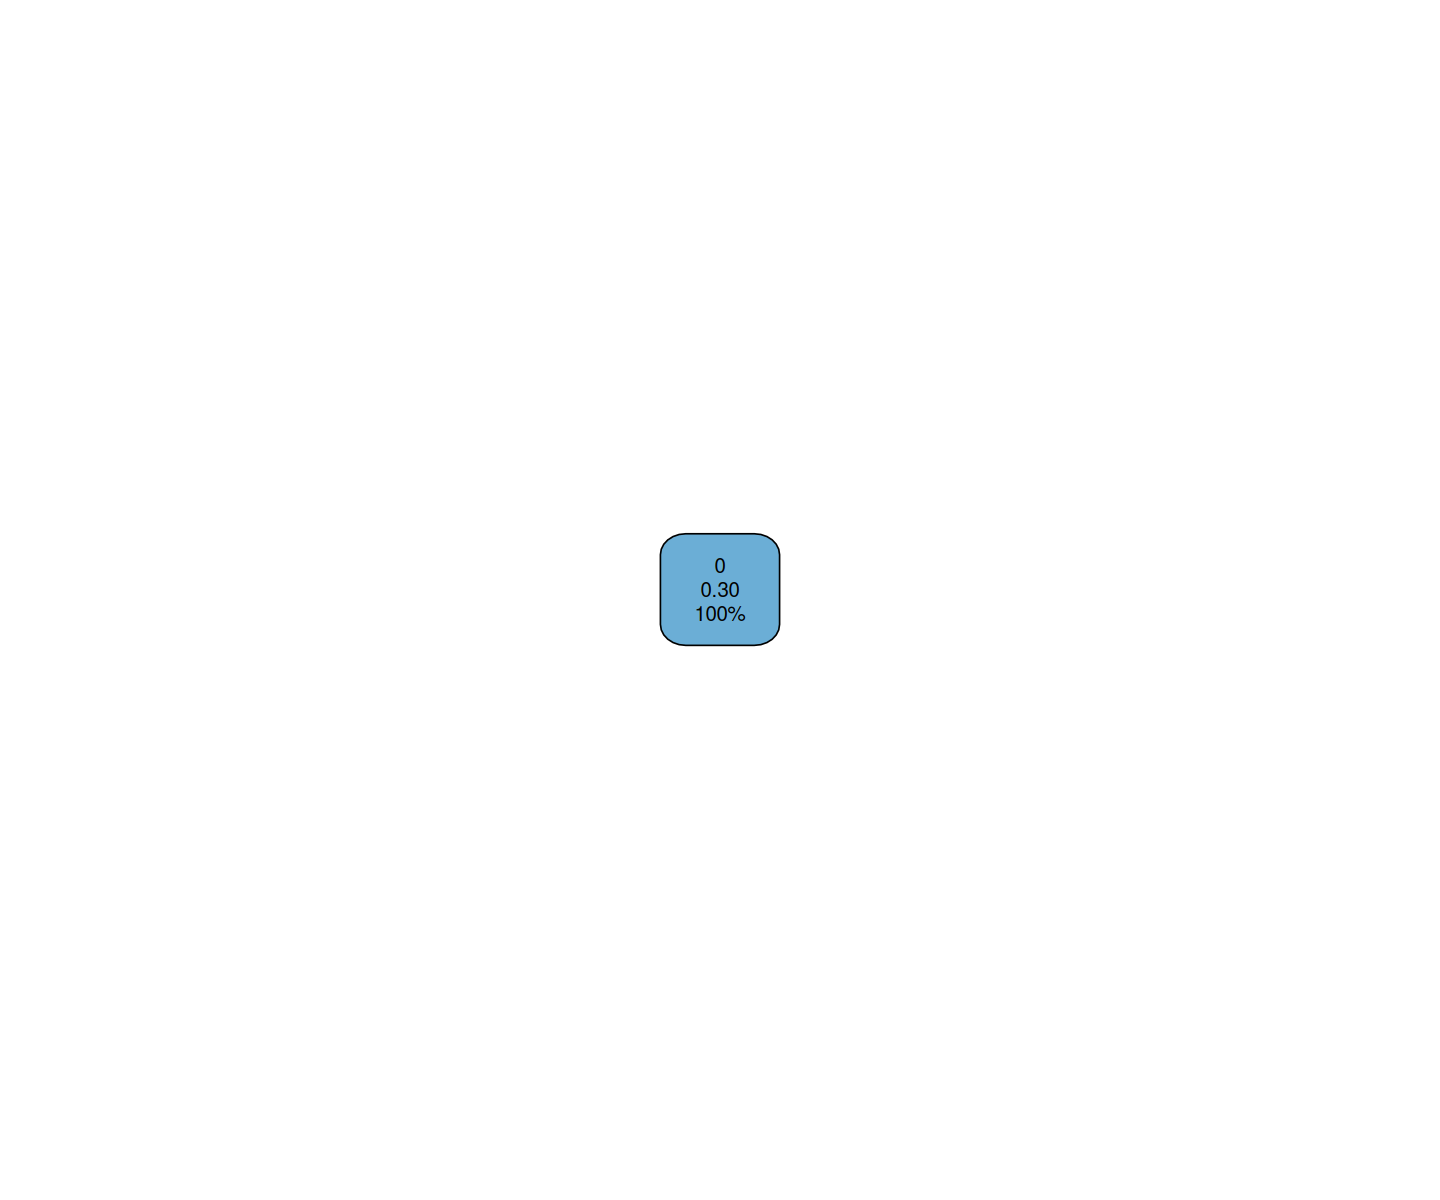

In [82]:
grafdim(12,10)
rpart.plot(modelo)

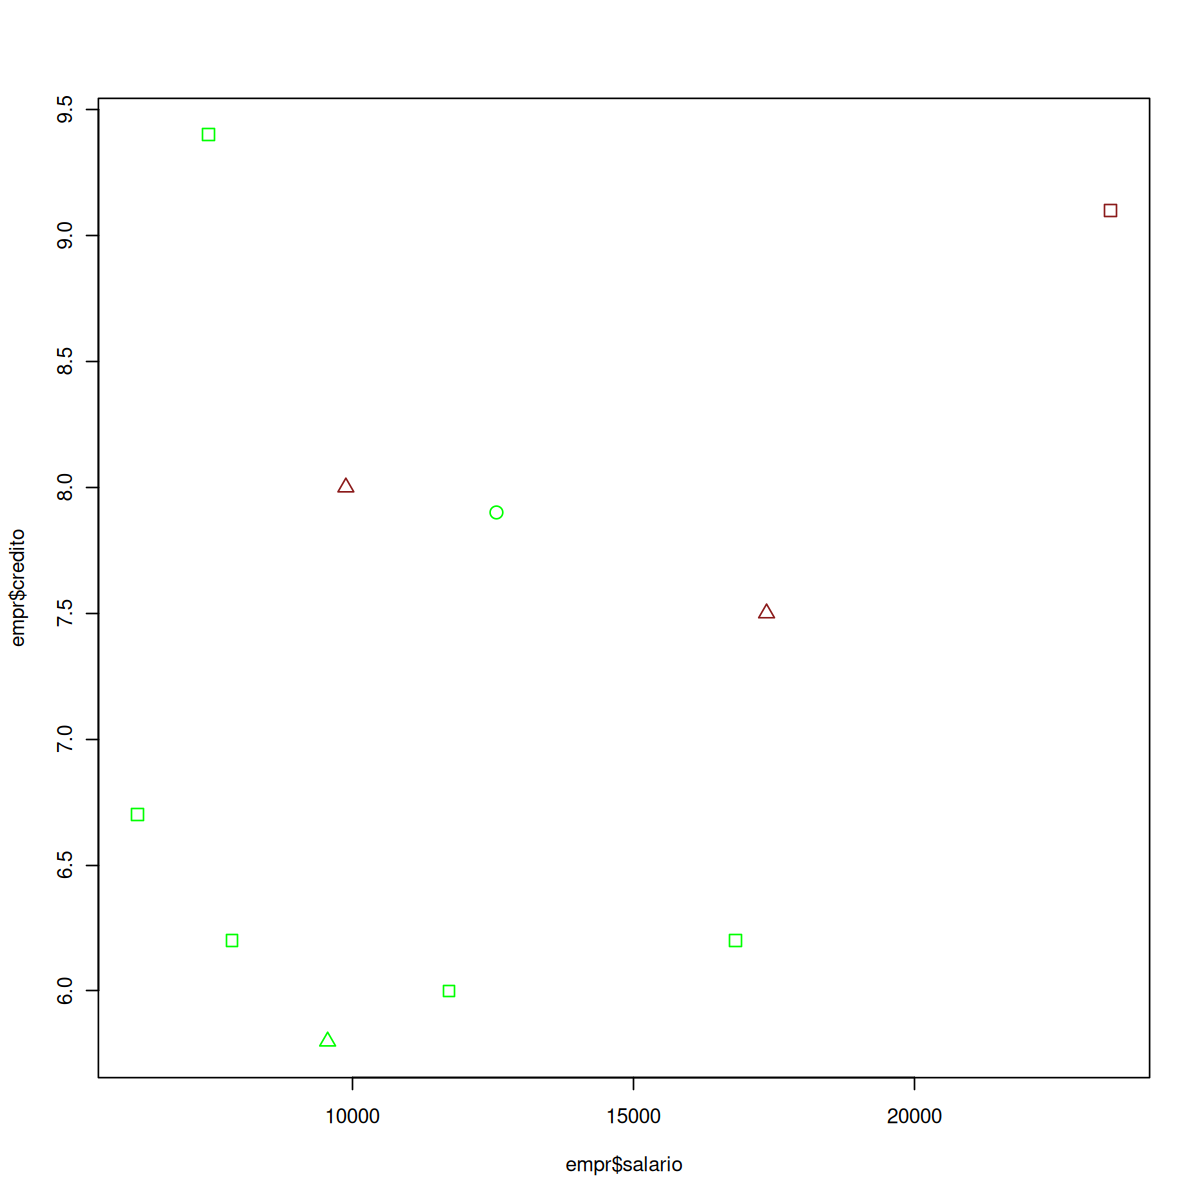

In [84]:
grafdim(10,10)
cor_classe <- c("green",        # 0 - negativo, sem empréstimo
                "firebrick4")   # 1 - positivo, emprétimo concedido
tipo_ponto <- c(1,2,0) # o -> médio,  ⃤ -> superior,  ⃞ -> pós
plot(empr$salario,empr$credito, cex=1.3,
     col=cor_classe[as.numeric(empr$emprest)],
     pch=tipo_ponto[as.numeric(empr$educacao)]) # pode ser empr$sexo ou civil

#### Dados de treino, teste e validação

Construção dos conjuntos de treino, teste e validação

In [27]:
(num_obs   <- nrow(empr))
tx_teste   <- 0.20
tx_valid   <- 0.20
(num_teste <- trunc(num_obs * tx_teste))
(num_valid <- trunc(num_obs * tx_valid))
(num_trein <- num_obs - num_teste - num_valid)

[1] 1000

[1] 200

[1] 200

[1] 600

In [28]:
treino <- empr
amostra  <- sample(1:num_obs, num_teste, replace=FALSE)
teste  <- treino[ amostra, ]
treino <- treino[-amostra, ]
amostra  <- sample(1:(num_obs - num_teste), num_valid, replace=FALSE)
valid  <- treino[ amostra, ]
treino <- treino[-amostra, ]
head(treino)
head(valid)

,civil,sexo,educacao,credito,salario,emprest
,<fct>,<fct>,<ord>,<dbl>,<dbl>,<fct>
2,solteiro,M,superior,9,11962.3,0
4,solteiro,F,pós-graduação,7,8517.8,0
5,solteiro,F,superior,9,14218.2,0
7,solteiro,M,médio,6,16359.3,0
8,casado,M,superior,9,13796.0,1
9,casado,M,superior,6,6595.6,0


,civil,sexo,educacao,credito,salario,emprest
,<fct>,<fct>,<ord>,<dbl>,<dbl>,<fct>
337,casado,M,pós-graduação,8,6480.6,0
392,casado,F,pós-graduação,9,13225.0,1
24,casado,M,superior,6,10590.9,1
551,casado,F,médio,9,11423.5,0
260,solteiro,F,pós-graduação,8,25688.3,1
502,casado,F,médio,8,11672.7,0


#### Modelo de Árvore de Decisão

Aderindo um modelo através de `rpart`:

In [14]:
modelo_ad = rpart(emprest ~ a + b, data=df_trein, control=rpart.control(cp = 0.0001))

In [15]:
printcp(fit)


Classification tree:
rpart(formula = classe ~ a + b, data = df_trein, control = rpart.control(cp = 1e-04))

Variables actually used in tree construction:
[1] a b

Root node error: 71/120 = 0.6

n= 120 

     CP nsplit rel error xerror xstd
1 3e-01      0       1.0    1.0 0.08
2 2e-01      1       0.7    0.9 0.08
3 8e-02      2       0.5    0.6 0.07
4 1e-04      3       0.4    0.5 0.07


In [16]:
fit

n= 120 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

1) root 120 71 normal (0.3250 0.4083 0.2667)  
  2) b< 8.5 52 18 baixo (0.6538 0.2692 0.0769)  
    4) a< 14.5 40  7 baixo (0.8250 0.1750 0.0000) *
    5) a>=14.5 12  5 normal (0.0833 0.5833 0.3333) *
  3) b>=8.5 68 33 normal (0.0735 0.5147 0.4118)  
    6) a< 12.5 40 11 normal (0.1250 0.7250 0.1500) *
    7) a>=12.5 28  6 alto (0.0000 0.2143 0.7857) *

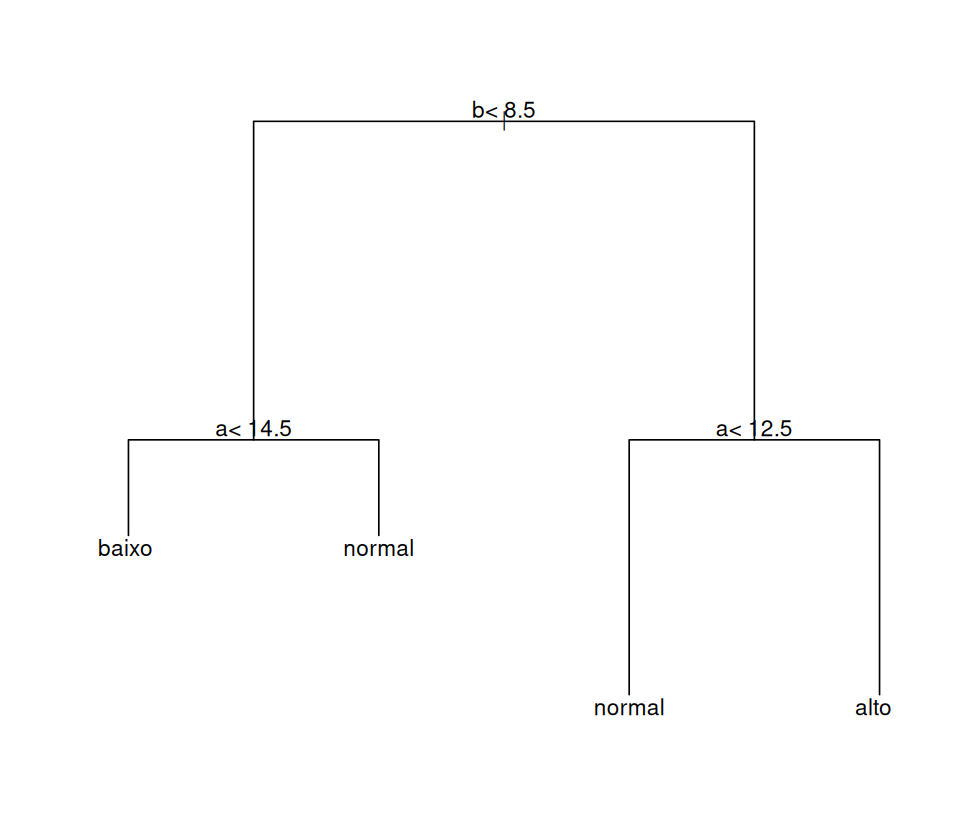

In [17]:
grafdim(8,7)
plot(fit)
text(fit, cex = 1.1, xpd = TRUE)

In [58]:
grafdim(9,8)
rpart.plot(fit)

: [1m[33mError[39m:[22m
[33m![39m object 'fit' not found

In [19]:
predito <- predict(fit, df_valid, type="class")

In [20]:
head(data.frame(df_valid$classe, predito),10)

,df_valid.classe,predito
,<ord>,<fct>
51,alto,alto
128,normal,normal
67,alto,alto
105,baixo,baixo
9,normal,alto
86,normal,normal
10,normal,normal
93,normal,normal
100,normal,normal


##### Qualidade do modelo

In [21]:
confusionMatrix(reference = df_valid$classe, data=predito)

Confusion Matrix and Statistics

          Reference
Prediction baixo normal alto
    baixo      8      2    2
    normal     2     12    5
    alto       0      2    7

Overall Statistics
                                        
               Accuracy : 0.675         
                 95% CI : (0.509, 0.814)
    No Information Rate : 0.4           
    P-Value [Acc > NIR] : 0.000402      
                                        
                  Kappa : 0.505         
                                        
 Mcnemar's Test P-Value : 0.349636      

Statistics by Class:

                     Class: baixo Class: normal Class: alto
Sensitivity                 0.800         0.750       0.500
Specificity                 0.867         0.708       0.923
Pos Pred Value              0.667         0.632       0.778
Neg Pred Value              0.929         0.810       0.774
Prevalence                  0.250         0.400       0.350
Detection Rate              0.200         0.300       0.175

#### Modelo de Árvore de Decisão Podada

In [25]:
fit.poda = prune(fit, cp=0.22)
printcp(fit.poda)


Classification tree:
rpart(formula = classe ~ a + b, data = df_trein, control = rpart.control(cp = 1e-04))

Variables actually used in tree construction:
[1] a b

Root node error: 71/120 = 0.6

n= 120 

   CP nsplit rel error xerror xstd
1 0.3      0       1.0    1.0 0.08
2 0.2      1       0.7    0.9 0.08
3 0.2      2       0.5    0.6 0.07


In [26]:
fit.poda

n= 120 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

1) root 120 71 normal (0.3250 0.4083 0.2667)  
  2) b< 8.5 52 18 baixo (0.6538 0.2692 0.0769) *
  3) b>=8.5 68 33 normal (0.0735 0.5147 0.4118)  
    6) a< 12.5 40 11 normal (0.1250 0.7250 0.1500) *
    7) a>=12.5 28  6 alto (0.0000 0.2143 0.7857) *

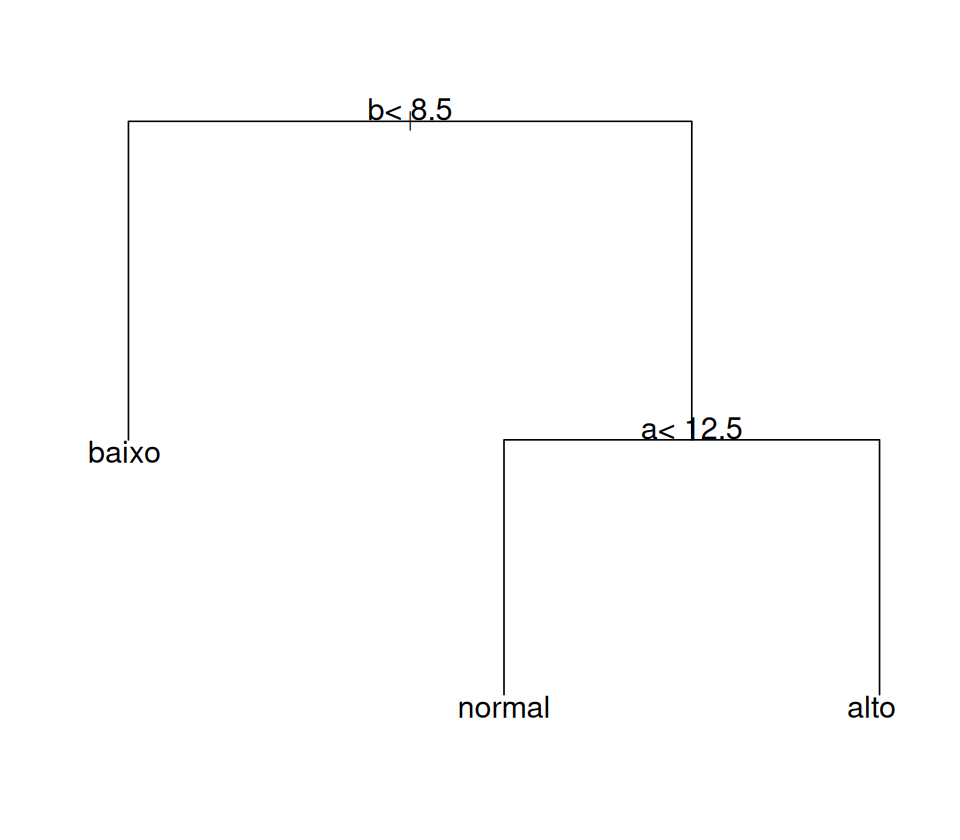

In [27]:
grafdim(8,7)
plot(fit.poda)
text(fit.poda, cex=1.5, xpd=TRUE)

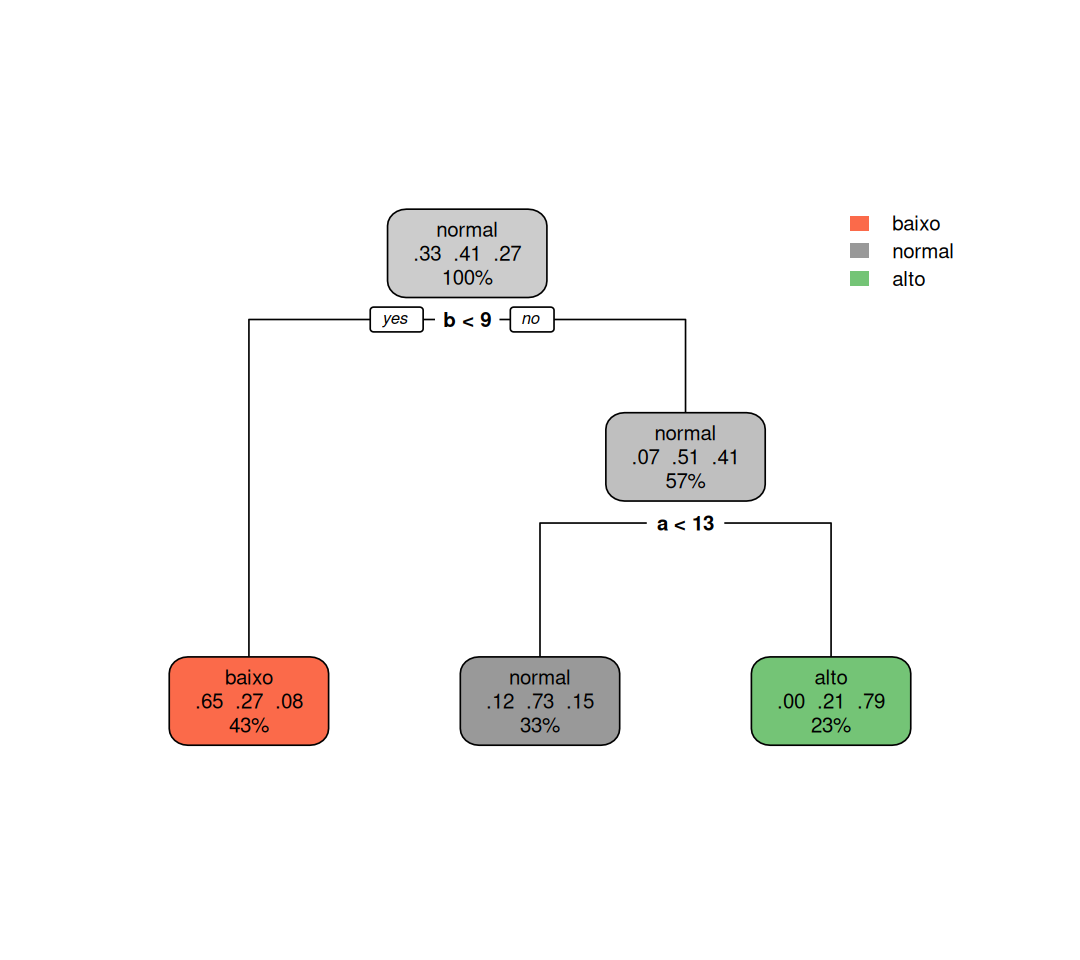

In [28]:
grafdim(9,8)
rpart.plot(fit.poda)

Verificar qualidade do modelo com os dados de validação:

In [29]:
predito <- predict(fit.poda, df_valid, type="class")

In [30]:
head(data.frame(df_valid$classe, predito),10)

,df_valid.classe,predito
,<ord>,<fct>
51,alto,alto
128,normal,baixo
67,alto,alto
105,baixo,baixo
9,normal,alto
86,normal,normal
10,normal,normal
93,normal,normal
100,normal,normal


##### Qualidade do modelo

In [31]:
confusionMatrix(reference = df_valid$classe, data=predito)

Confusion Matrix and Statistics

          Reference
Prediction baixo normal alto
    baixo      8      4    4
    normal     2     10    3
    alto       0      2    7

Overall Statistics
                                        
               Accuracy : 0.625         
                 95% CI : (0.458, 0.773)
    No Information Rate : 0.4           
    P-Value [Acc > NIR] : 0.00335       
                                        
                  Kappa : 0.441         
                                        
 Mcnemar's Test P-Value : 0.18182       

Statistics by Class:

                     Class: baixo Class: normal Class: alto
Sensitivity                 0.800         0.625       0.500
Specificity                 0.733         0.792       0.923
Pos Pred Value              0.500         0.667       0.778
Neg Pred Value              0.917         0.760       0.774
Prevalence                  0.250         0.400       0.350
Detection Rate              0.200         0.250       0.175

#### Conjunto de modelos com `caret::train`

In [32]:
controles <- trainControl(method="cv", number=10)

In [33]:
fit.caret <- caret::train(classe ~ ., data=df_trein, trControl=controles, method="rpart")

In [34]:
fit.caret

CART 

120 samples
  2 predictor
  3 classes: 'baixo', 'normal', 'alto' 

No pre-processing
Resampling: Cross-Validated (10 fold) 
Summary of sample sizes: 110, 108, 108, 108, 108, 107, ... 
Resampling results across tuning parameters:

  cp      Accuracy  Kappa
  0.0845  0.693     0.536
  0.2254  0.575     0.335
  0.2817  0.457     0.107

Accuracy was used to select the optimal model using the largest value.
The final value used for the model was cp = 0.0845.

In [35]:
predito <- predict(fit.caret, df_valid)

In [36]:
confusionMatrix(reference = df_valid$classe, data = predito)

Confusion Matrix and Statistics

          Reference
Prediction baixo normal alto
    baixo      8      4    4
    normal     2     10    3
    alto       0      2    7

Overall Statistics
                                        
               Accuracy : 0.625         
                 95% CI : (0.458, 0.773)
    No Information Rate : 0.4           
    P-Value [Acc > NIR] : 0.00335       
                                        
                  Kappa : 0.441         
                                        
 Mcnemar's Test P-Value : 0.18182       

Statistics by Class:

                     Class: baixo Class: normal Class: alto
Sensitivity                 0.800         0.625       0.500
Specificity                 0.733         0.792       0.923
Pos Pred Value              0.500         0.667       0.778
Neg Pred Value              0.917         0.760       0.774
Prevalence                  0.250         0.400       0.350
Detection Rate              0.200         0.250       0.175

### Caso 2 - Fraude no Seguro

[Referência](https://www.gormanalysis.com/blog/decision-trees-in-r-using-rpart/)

Bibliotecas

In [37]:
rm(list=ls())
library(rpart)  # árvores de decisão
library(repr)   # representações (ajuste gráfico do jupyter)
library(caret)  # matriz de confusão

library(rpart.plot)
library(RColorBrewer)

In [38]:
grafdim <- function(x=11, y=9) { options(repr.plot.width=x, repr.plot.height=y) }
grafdim()

Preparação do ambiente

In [167]:
set.seed(1701)

#### Dados

In [168]:
tamanho <- 1000
empr <- data.frame(
  # 30% de solteiros, 70% de casados  
  civil    = factor(sample(c('solteiro','casado'), tamanho, 
                           replace=TRUE, prob=c(0.3, 0.7))),
  # 50% de sexo 'M', 50% de 'F'
  sexo     = factor(sample(c('M','F'), tamanho, 
                           replace=TRUE, prob=c(0.5, 0.5))),
  # 20% com ensino médio, 60% com superior e 20% com pós
  educacao = factor(sample(c("médio", "superior", "pós-graduação"), 
                           tamanho, replace=TRUE,
                           prob=c(0.2, 0.6, 0.2)), ordered=TRUE),
  # crédito tem distribuição uniforme [0,55; 0,95]
  credito  = round(runif(tamanho, 0.55, 0.95), 1) * 10, 
  # salário tem distribuição Weibull com forma 1,6 e escala 2
  # para ser assimétrico, com cauda longa à direita
  salario  = round(rweibull(tamanho,1.6,2)*40,3)*100 + 5000
)
# "regras" (secretas) para conceder um empréstimo
empr$emprest <- factor(as.numeric(
    empr$civil == 'solteiro' & (empr$sexo == 'F' & empr$credito > 7.5 & empr$salario > 15000 |
                                empr$sexo == 'M' & empr$credito > 9.0) |
    empr$salario > 25000 & empr$credito > 0.7 |
    empr$educacao == 'superior' & empr$salario > 10000 & 
                     empr$credito > 0.6 & empr$civil == 'casado' |
    empr$educacao == 'pós-graduação' & empr$credito > 7.0 & empr$salario > 7000
    ))

In [169]:
summary(empr)

      civil     sexo             educacao      credito        salario     
 casado  :686   F:492   médio        :213   Min.   :6.00   Min.   : 5121  
 solteiro:314   M:508   pós-graduação:215   1st Qu.:7.00   1st Qu.: 8853  
                        superior     :572   Median :7.00   Median :11520  
                                            Mean   :7.45   Mean   :12275  
                                            3rd Qu.:8.00   3rd Qu.:14723  
                                            Max.   :9.00   Max.   :37474  
 emprest
 0:643  
 1:357  
        
        
        
        

In [170]:
head(empr, 10)

,civil,sexo,educacao,credito,salario,emprest
,<fct>,<fct>,<ord>,<dbl>,<dbl>,<fct>
1,casado,F,pós-graduação,9,17166,1
2,solteiro,F,pós-graduação,6,18578,0
3,casado,M,superior,7,5463,0
4,casado,F,superior,7,8046,0
5,solteiro,F,médio,8,18387,1
6,casado,M,superior,8,14281,1
7,casado,F,superior,9,11950,1
8,casado,M,superior,6,8146,0
9,casado,M,pós-graduação,6,14401,0


In [171]:
modelo = rpart(emprest ~ civil + sexo + educacao + credito + salario, data=empr)

In [172]:
modelo

n= 1000 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

 1) root 1000 357 0 (0.6430 0.3570)  
   2) salario< 9.97e+03 354  32 0 (0.9096 0.0904)  
     4) educacao=superior 219   0 0 (1.0000 0.0000) *
     5) educacao=médio,pós-graduação 135  32 0 (0.7630 0.2370)  
      10) educacao=médio 68   0 0 (1.0000 0.0000) *
      11) educacao=pós-graduação,superior 67  32 0 (0.5224 0.4776)  
        22) credito< 7.5 27   0 0 (1.0000 0.0000) *
        23) credito>=7.5 40   8 1 (0.2000 0.8000)  
          46) salario< 6.91e+03 8   0 0 (1.0000 0.0000) *
          47) salario>=6.91e+03 32   0 1 (0.0000 1.0000) *
   3) salario>=9.97e+03 646 321 1 (0.4969 0.5031)  
     6) educacao=médio 145   9 0 (0.9379 0.0621) *
     7) educacao=pós-graduação,superior 501 185 1 (0.3693 0.6307)  
      14) civil=solteiro 154  26 0 (0.8312 0.1688)  
        28) credito< 7.5 92   3 0 (0.9674 0.0326) *
        29) credito>=7.5 62  23 0 (0.6290 0.3710)  
          58) educacao=superior 46   7 0 (0

In [173]:
printcp(modelo)


Classification tree:
rpart(formula = emprest ~ civil + sexo + educacao + credito + 
    salario, data = empr)

Variables actually used in tree construction:
[1] civil    credito  educacao salario 

Root node error: 357/1000 = 0.4

n= 1000 

    CP nsplit rel error xerror xstd
1 0.18      0      1.00   1.00 0.04
2 0.08      3      0.35   0.35 0.03
3 0.02      5      0.19   0.19 0.02
4 0.01     11      0.06   0.06 0.01


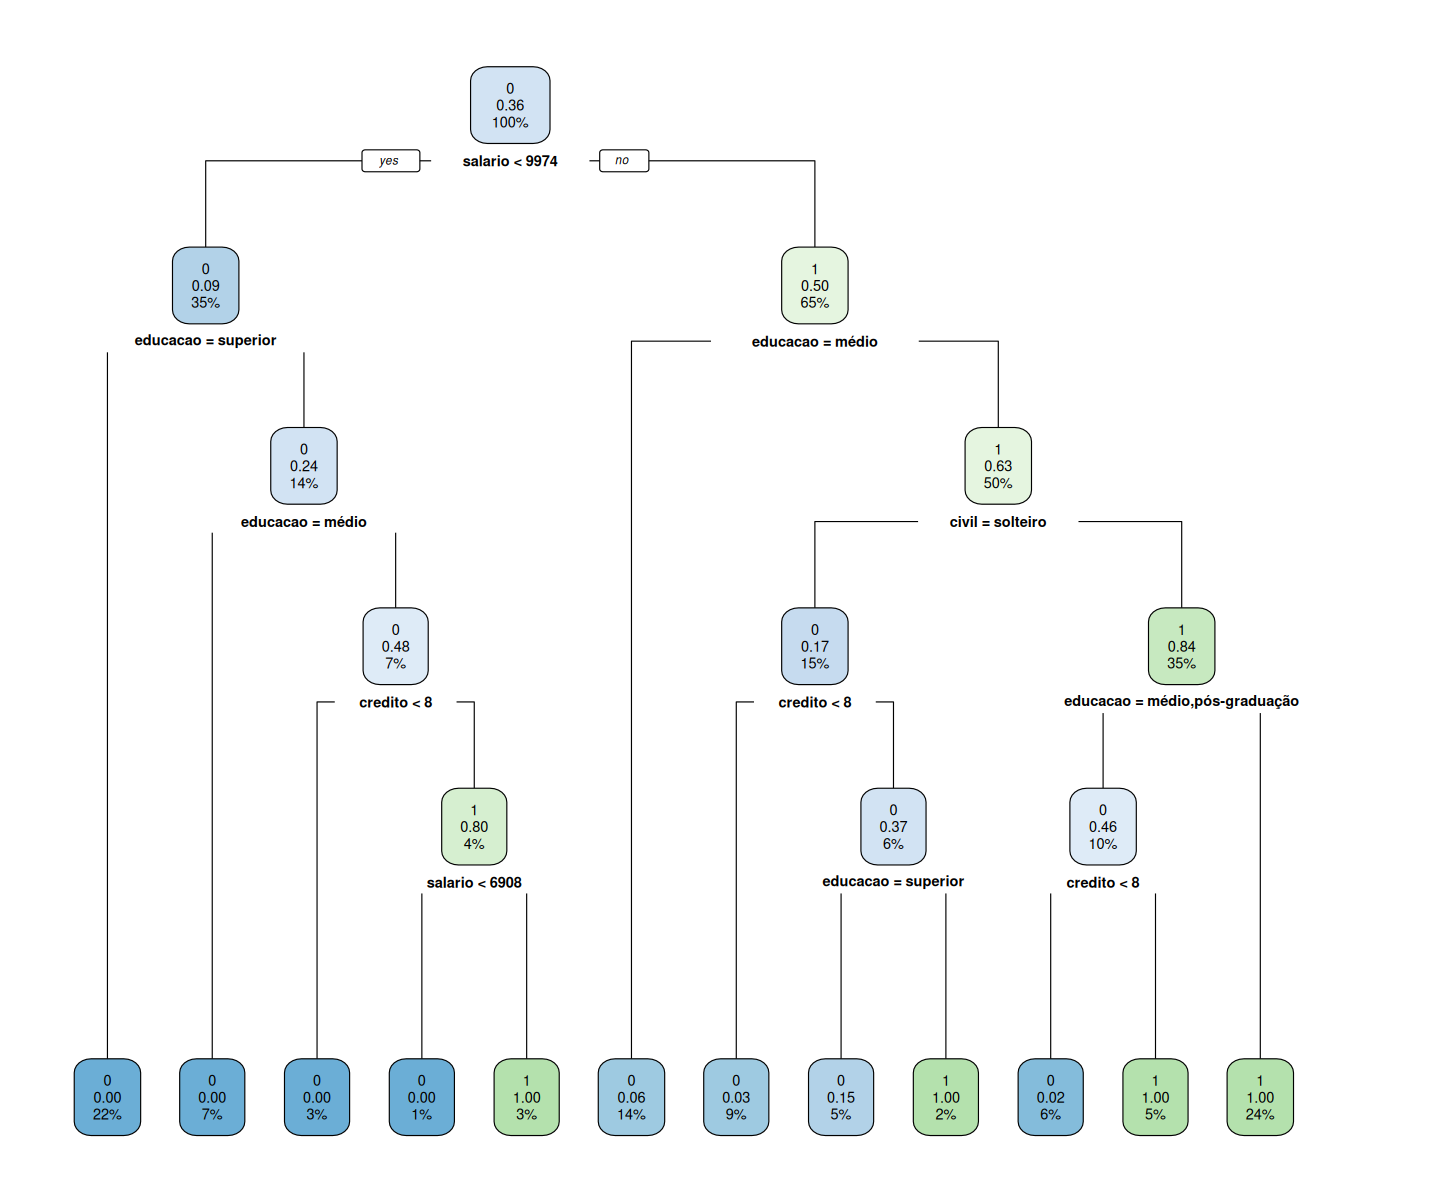

In [174]:
grafdim(12,10)
rpart.plot(modelo)

In [40]:
treino <- data.frame(
  ClaimID = c(1,2,3),
  RearEnd = c(TRUE, FALSE, TRUE),
  Fraud   = c(TRUE, FALSE, TRUE) )

In [41]:
treino

ClaimID,RearEnd,Fraud
<dbl>,<lgl>,<lgl>
1,TRUE,TRUE
2,FALSE,FALSE
3,TRUE,TRUE


#### Modelo

In [42]:
tree <- rpart(Fraud ~ RearEnd, data=treino, method="class")

In [43]:
printcp(tree)


Classification tree:
rpart(formula = Fraud ~ RearEnd, data = treino, method = "class")

Variables actually used in tree construction:
character(0)

Root node error: 1/3 = 0.3

n= 3 

    CP nsplit rel error xerror xstd
1 0.01      0         1      0    0


In [44]:
tree

n= 3 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

1) root 3 1 TRUE (0.333 0.667) *

A análise criou apenas o nó raiz pois os parâmetros por omissão de `rpart` preveniram a árvore de crescer, especificamente `minsplit` e `minbucket`.

In [45]:
tree <- rpart(Fraud ~ RearEnd, data=treino, 
              method="class", 
              minsplit=2, minbucket=1)

In [46]:
printcp(tree)


Classification tree:
rpart(formula = Fraud ~ RearEnd, data = treino, method = "class", 
    minsplit = 2, minbucket = 1)

Variables actually used in tree construction:
[1] RearEnd

Root node error: 1/3 = 0.3

n= 3 

    CP nsplit rel error xerror xstd
1 1.00      0         1      3  0.0
2 0.01      1         0      1  0.8


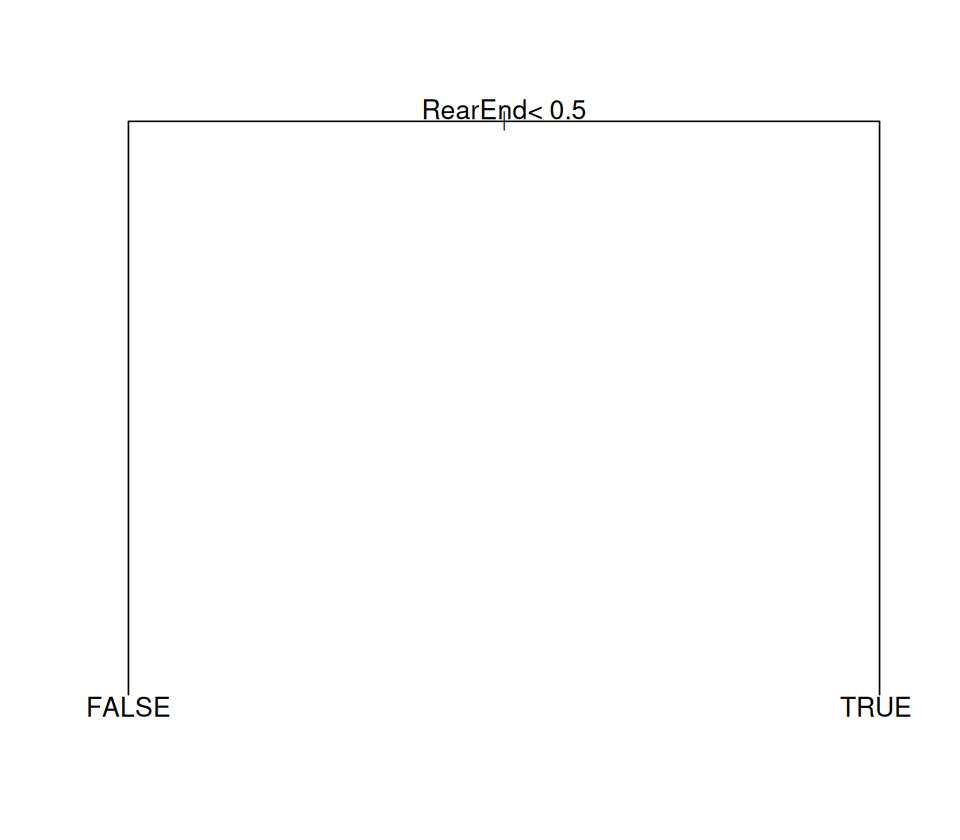

In [47]:
grafdim(8,7)
plot(tree)
text(tree, cex=1.3, xpd=TRUE)

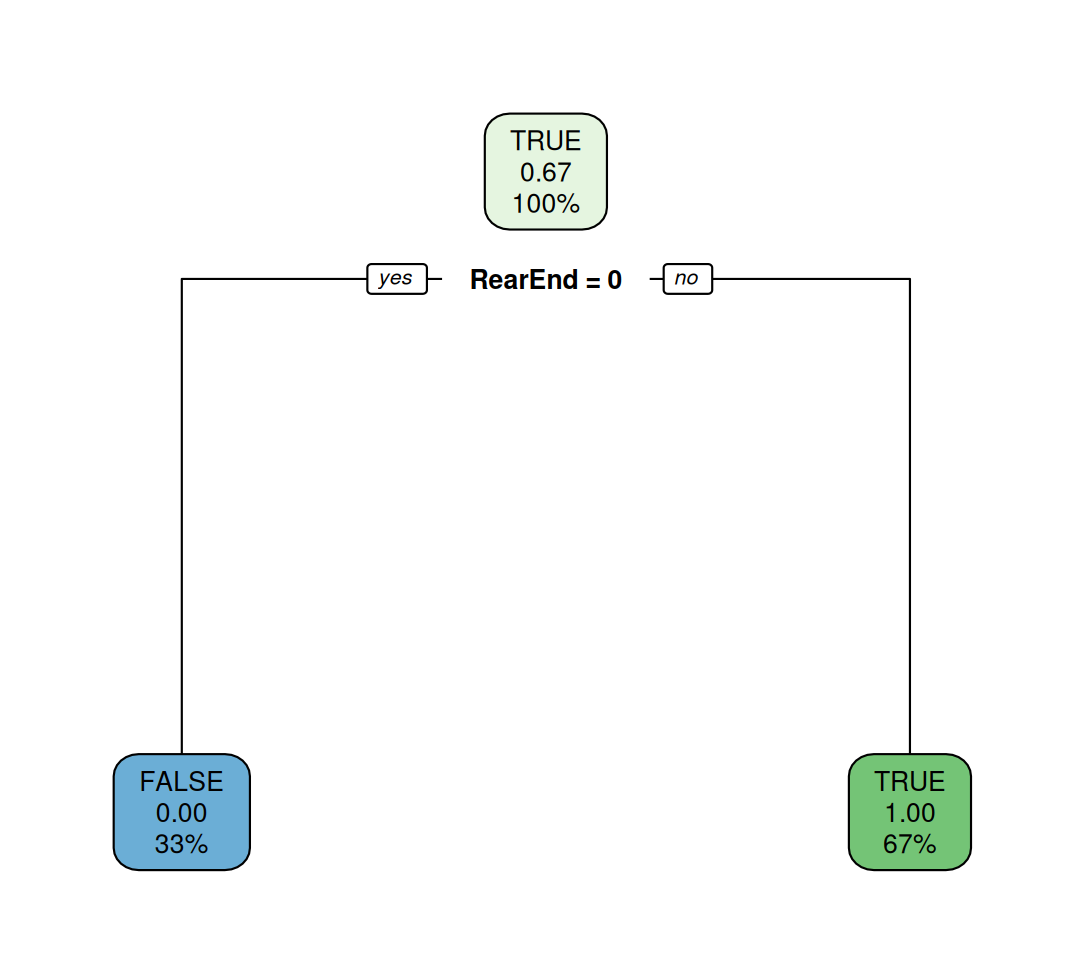

In [48]:
grafdim(9,8)
rpart.plot(tree, cex=1.3)

`rpart` utiliza índice de Gini como indicador de impureza para dividir os nós. Pode ser usado o ganho de informação (entropia):

In [49]:
tree.info <- rpart(Fraud ~ RearEnd, data=treino, 
                   method="class",
                   parms=list(split = 'information'),
                   minsplit=2, minbucket=1)

In [50]:
printcp(tree.info)


Classification tree:
rpart(formula = Fraud ~ RearEnd, data = treino, method = "class", 
    parms = list(split = "information"), minsplit = 2, minbucket = 1)

Variables actually used in tree construction:
[1] RearEnd

Root node error: 1/3 = 0.3

n= 3 

    CP nsplit rel error xerror xstd
1 1.00      0         1      3  0.0
2 0.01      1         0      1  0.8


In [51]:
tree.info

n= 3 

node), split, n, loss, yval, (yprob)
      * denotes terminal node

1) root 3 1 TRUE (0.333 0.667)  
  2) RearEnd< 0.5 1 0 FALSE (1.000 0.000) *
  3) RearEnd>=0.5 2 0 TRUE (0.000 1.000) *

Com mais impureza:

#### Modelo com peso

In [52]:
treino <- data.frame(
  ClaimID = c(   1,     2,     3,     4,    5,     6,     7),
  RearEnd = c(TRUE, FALSE,  TRUE, FALSE, TRUE,  TRUE, FALSE),
  Fraud   = c(TRUE, FALSE, FALSE,  TRUE, TRUE, FALSE, FALSE))

In [53]:
treino

ClaimID,RearEnd,Fraud
<dbl>,<lgl>,<lgl>
1,TRUE,TRUE
2,FALSE,FALSE
3,TRUE,FALSE
4,FALSE,TRUE
5,TRUE,TRUE
6,TRUE,FALSE
7,FALSE,FALSE


In [54]:
tree <- rpart(Fraud ~ RearEnd, data=treino, 
              method="class", 
              minsplit=2, minbucket=1)

In [55]:
printcp(tree)


Classification tree:
rpart(formula = Fraud ~ RearEnd, data = treino, method = "class", 
    minsplit = 2, minbucket = 1)

Variables actually used in tree construction:
character(0)

Root node error: 3/7 = 0.4

n= 7 

  CP nsplit rel error xerror xstd
1  0      0         1      0    0


O algoritmo de crescimento da árvore do `rpart` não crescerá a árvore se sua complexidade crescer mais que a capacidade de explicação do modelo, ou seja, se o tamanho da árvore aumentar mas não sua capacidade de separação de classes. Para impedir que o algoritmo interrompa o crescimento (ou seja, garanta o crescimento) é necessário dar um valor negativo para o parâmetro `cp`.

In [56]:
tree <- rpart(Fraud ~ RearEnd, data=treino, 
              method="class", 
              minsplit=2, minbucket=1, cp=-1)

In [57]:
printcp(tree)


Classification tree:
rpart(formula = Fraud ~ RearEnd, data = treino, method = "class", 
    minsplit = 2, minbucket = 1, cp = -1)

Variables actually used in tree construction:
[1] RearEnd

Root node error: 3/7 = 0.4

n= 7 

  CP nsplit rel error xerror xstd
1  0      0         1      2  0.4
2 -1      1         1      2  0.4


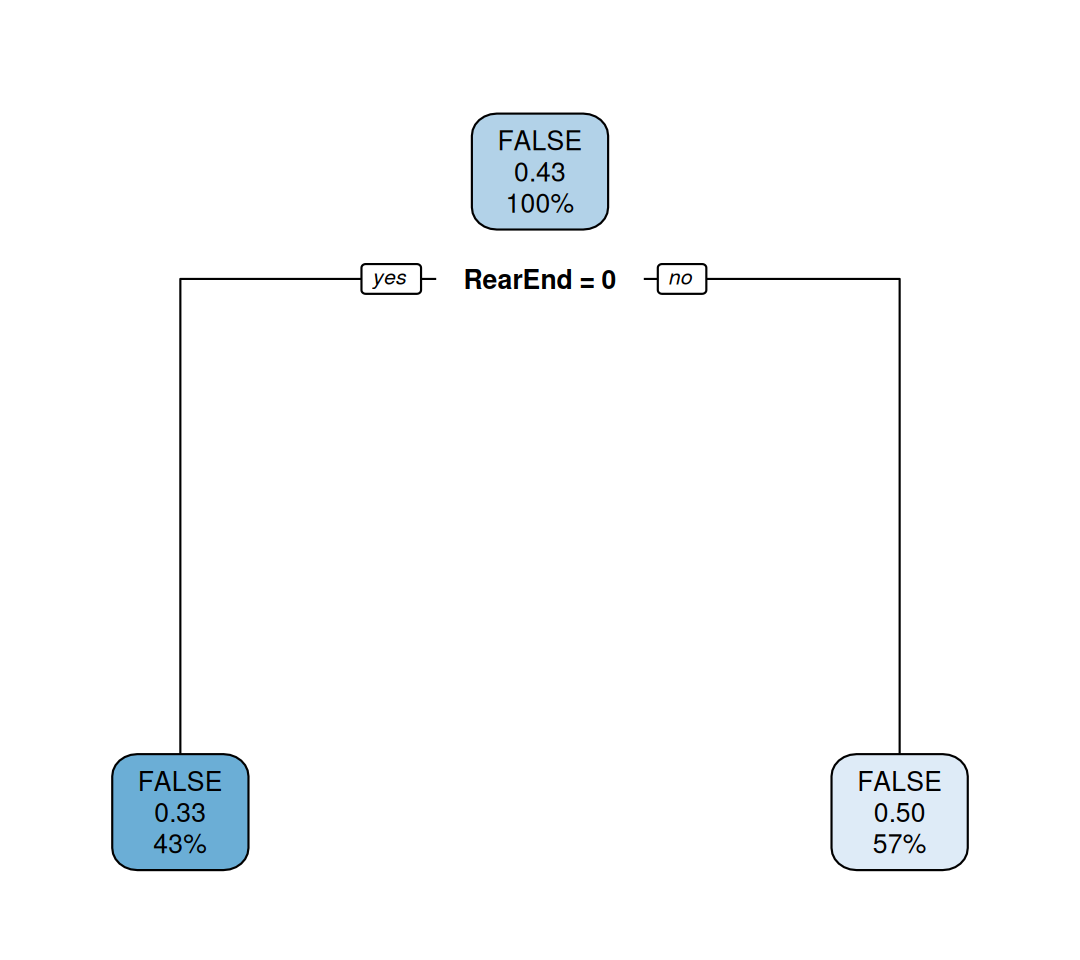

In [58]:
grafdim(9,8)
rpart.plot(tree, cex=1.3)

Fica claro que crescer a árvore não proporcionou ganho. Havia 43% (3/7) de casos de fraude. A árvore recomenda: se não for batida traseira (`RearEnd = 0`, ou seja `FALSE`) considere não fraude (com erro de 0,33) e se for batida traseira (`RearEnd ≠ 0`, ou seja `TRUE`), considere não fraude com erro de 50%.

Forçar o crescimento da árvore em geral produz modelo com _overfitting_ .

Pode-se fornecer um peso para cada observação, indicando a importância dela para a modelagem:

In [59]:
tree <- rpart(Fraud ~ RearEnd, data=treino, method="class", 
              minsplit=2, minbucket=1,
              weights=c(0.16,0.16,0.12,0.12,0.16,0.12,0.16), cp=-1)

In [60]:
printcp(tree)


Classification tree:
rpart(formula = Fraud ~ RearEnd, data = treino, weights = c(0.16, 
    0.16, 0.12, 0.12, 0.16, 0.12, 0.16), method = "class", minsplit = 2, 
    minbucket = 1, cp = -1)

Variables actually used in tree construction:
[1] RearEnd

Root node error: 0.4/7 = 0.06

n= 7 

    CP nsplit rel error xerror xstd
1  0.2      0       1.0      2    1
2 -1.0      1       0.8      2    1


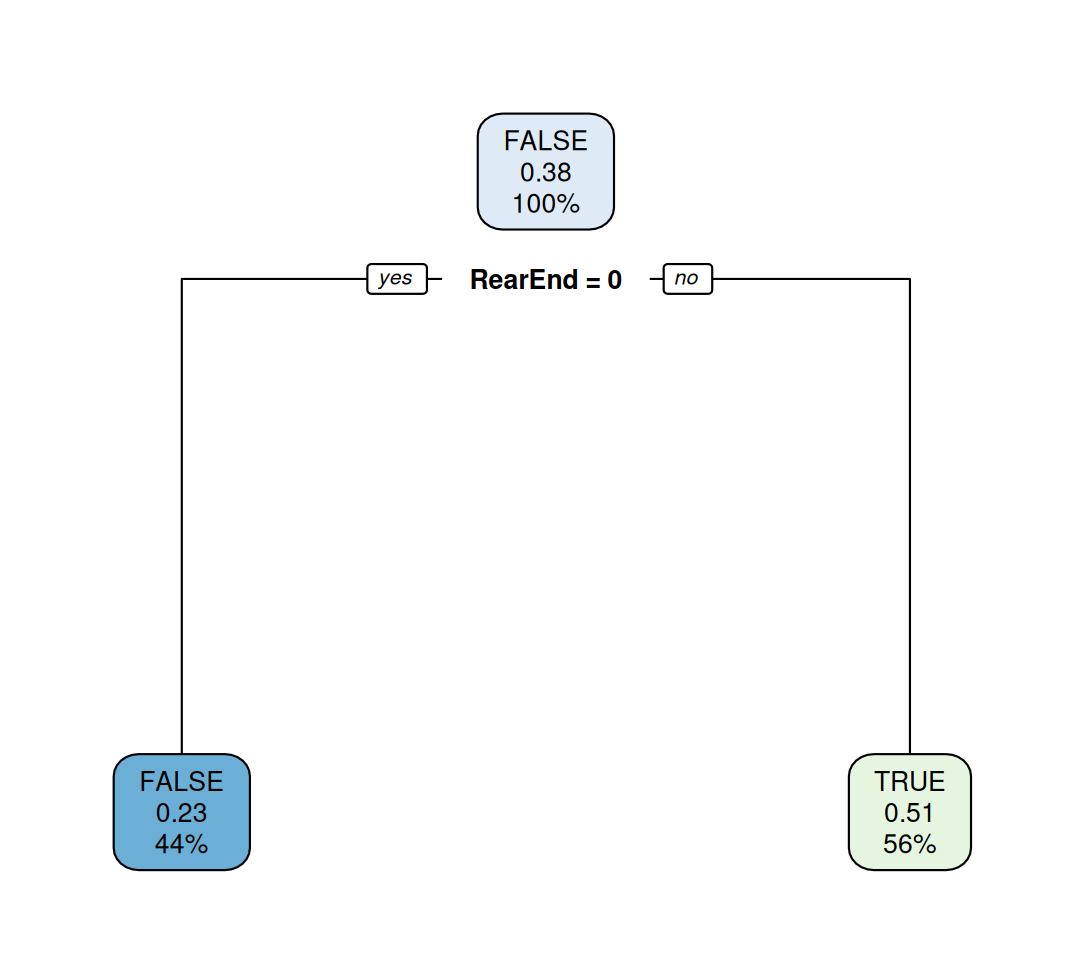

In [61]:
rpart.plot(tree, cex=1.3)

Se não for batida traseira, considere que não houve fraude, com erro de 23%; se foi batida traseira, considere fraude, com um erro de 49%.

#### Modelo com custo

Pode ser mais importante para quem investiga as fraudes um tipo de classificação errada que outra. No caso, classificar como fraude algo que não é (erros do Tipo I - falso positivo) é bem menos importante que não classificar como fraude uma fraude (erros Tipo II - falso negativo).  
A alteração da função de custo uniforme é feita fornecendo ao `rpart` uma matriz de custo que tem os pesos das classificações incorretas.  
A posição m<sub><i>i</i>,<i>j</i></sub> da matriz indica o custo de classificar _i_ por _j_ quando obviamente _i_ ≠ _j_. Portanto m<sub><i>i</i>,<i>i</i></sub> = 0.

In [62]:
treino <- data.frame(ClaimID=1:7,
  RearEnd  = c(TRUE, TRUE, FALSE, FALSE, FALSE, FALSE, FALSE),
  Whiplash = c(TRUE, TRUE,  TRUE,  TRUE,  TRUE, FALSE, FALSE),
  Fraud    = c(TRUE, TRUE,  TRUE, FALSE, FALSE, FALSE, FALSE) )

In [63]:
treino

ClaimID,RearEnd,Whiplash,Fraud
<int>,<lgl>,<lgl>,<lgl>
1,TRUE,TRUE,TRUE
2,TRUE,TRUE,TRUE
3,FALSE,TRUE,TRUE
4,FALSE,TRUE,FALSE
5,FALSE,TRUE,FALSE
6,FALSE,FALSE,FALSE
7,FALSE,FALSE,FALSE


In [64]:
tree.custo <- rpart(Fraud ~ RearEnd + Whiplash, 
                    data=treino, method="class",
                    maxdepth=1, minsplit=2, minbucket=1)

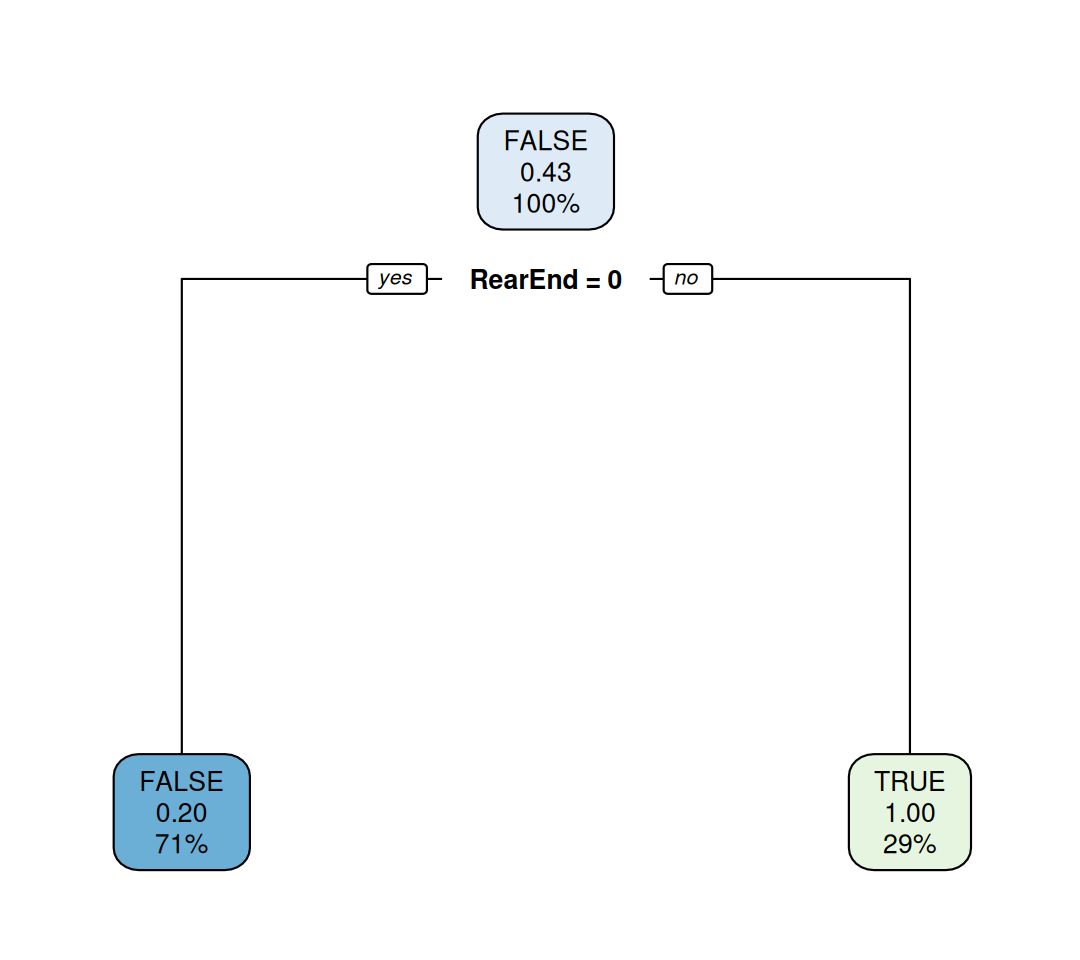

In [65]:
rpart.plot(tree.custo, cex=1.3)

O modelo identificou corretamente `RearEnd` como o critério de decisão. Porém um caso de fraude foi classificada incorretamente como não fraude. Para triplicar o custo de uma fraude classificada como fraude é preciso construir uma matriz de custo com os pesos.

In [66]:
predito <- predict(tree.custo, treino)

In [67]:
factor(predito[,1] > 0.5)

1     2     3     4     5     6     7 
FALSE FALSE  TRUE  TRUE  TRUE  TRUE  TRUE 
Levels: FALSE TRUE

In [68]:
treino$Fraud

[1]  TRUE  TRUE  TRUE FALSE FALSE FALSE FALSE

In [69]:
confusionMatrix(reference = factor(treino$Fraud), data = factor(predito[,1]>0.5))

Confusion Matrix and Statistics

          Reference
Prediction FALSE TRUE
     FALSE     0    2
     TRUE      4    1
                                        
               Accuracy : 0.143         
                 95% CI : (0.004, 0.579)
    No Information Rate : 0.571         
    P-Value [Acc > NIR] : 0.997         
                                        
                  Kappa : -0.615        
                                        
 Mcnemar's Test P-Value : 0.683         
                                        
            Sensitivity : 0.000         
            Specificity : 0.333         
         Pos Pred Value : 0.000         
         Neg Pred Value : 0.200         
             Prevalence : 0.571         
         Detection Rate : 0.000         
   Detection Prevalence : 0.286         
      Balanced Accuracy : 0.167         
                                        
       'Positive' Class : FALSE         
                                        

In [75]:
predito <- predict(tree.custo, treino)

In [76]:
treino$Fraud

[1]  TRUE  TRUE  TRUE FALSE FALSE FALSE FALSE

In [77]:
predito

,FALSE,TRUE
1,0.0,1.0
2,0.0,1.0
3,0.8,0.2
4,0.8,0.2
5,0.8,0.2
6,0.8,0.2
7,0.8,0.2


In [80]:
confusionMatrix(reference = factor(treino$Fraud), data=factor(predito[,2]>0.5))

Confusion Matrix and Statistics

          Reference
Prediction FALSE TRUE
     FALSE     4    1
     TRUE      0    2
                                        
               Accuracy : 0.857         
                 95% CI : (0.421, 0.996)
    No Information Rate : 0.571         
    P-Value [Acc > NIR] : 0.124         
                                        
                  Kappa : 0.696         
                                        
 Mcnemar's Test P-Value : 1.000         
                                        
            Sensitivity : 1.000         
            Specificity : 0.667         
         Pos Pred Value : 0.800         
         Neg Pred Value : 1.000         
             Prevalence : 0.571         
         Detection Rate : 0.571         
   Detection Prevalence : 0.714         
      Balanced Accuracy : 0.833         
                                        
       'Positive' Class : FALSE         
                                        

In [81]:
custo <- matrix(c(0,1,3,0), byrow=TRUE, nrow=2)
print(custo)

     [,1] [,2]
[1,]    0    1
[2,]    3    0


|  | fraude | não fraude | explicação |
|:-|:-:|:-:|:-|
| predito <br> como fraude | 0 | 1 | penalidade é `1` não ser fraude e dizer que é 
| predito como <br> não fraude | 3 | 0 | penalidade é `3` ser fraude mas dizer que não é

In [47]:
tree.custo <- rpart(Fraud ~ RearEnd + Whiplash, data=treino, 
                    method="class",
                    maxdepth=1, minsplit=2, minbucket=1,
                    parms=list(loss=custo) )

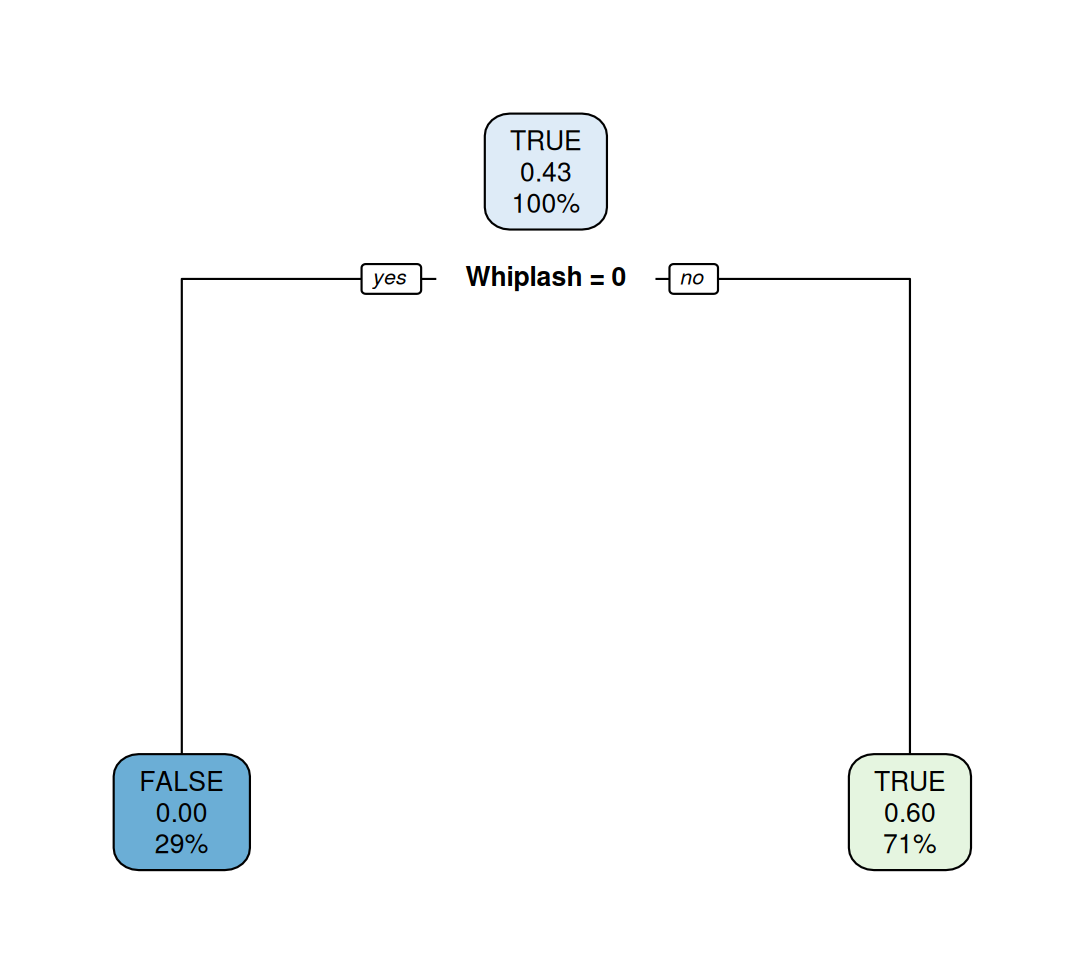

In [48]:
rpart.plot(tree.custo, cex=1.3)

Agora a variável preditora passou a ser `Wiplash`, acusando duas não fraudes como fraudes mas corretamente identificando todas fraudes.

#### Modelo com fator

É possível modelar utilizando uma variável com fatores.  Aqui tem um exemplo com o estado de atividade do segurado.

In [358]:
treino <- data.frame(
    ClaimID=c(1,2,3,4,5),
    Activity=factor(x=c("ativo", "ativo+", "ativo+", "inativo", "inativo-"),
                    levels = c("inativo-", "inativo", "ativo", "ativo+")),
    Fraud=c(FALSE, TRUE, TRUE, FALSE, TRUE) )

In [359]:
print(treino)

  ClaimID Activity Fraud
1       1    ativo FALSE
2       2   ativo+  TRUE
3       3   ativo+  TRUE
4       4  inativo FALSE
5       5 inativo-  TRUE


In [360]:
tree.fator <- rpart(Fraud ~ Activity, data=treino, 
                    method="class", 
                    minsplit=2, minbucket=1)

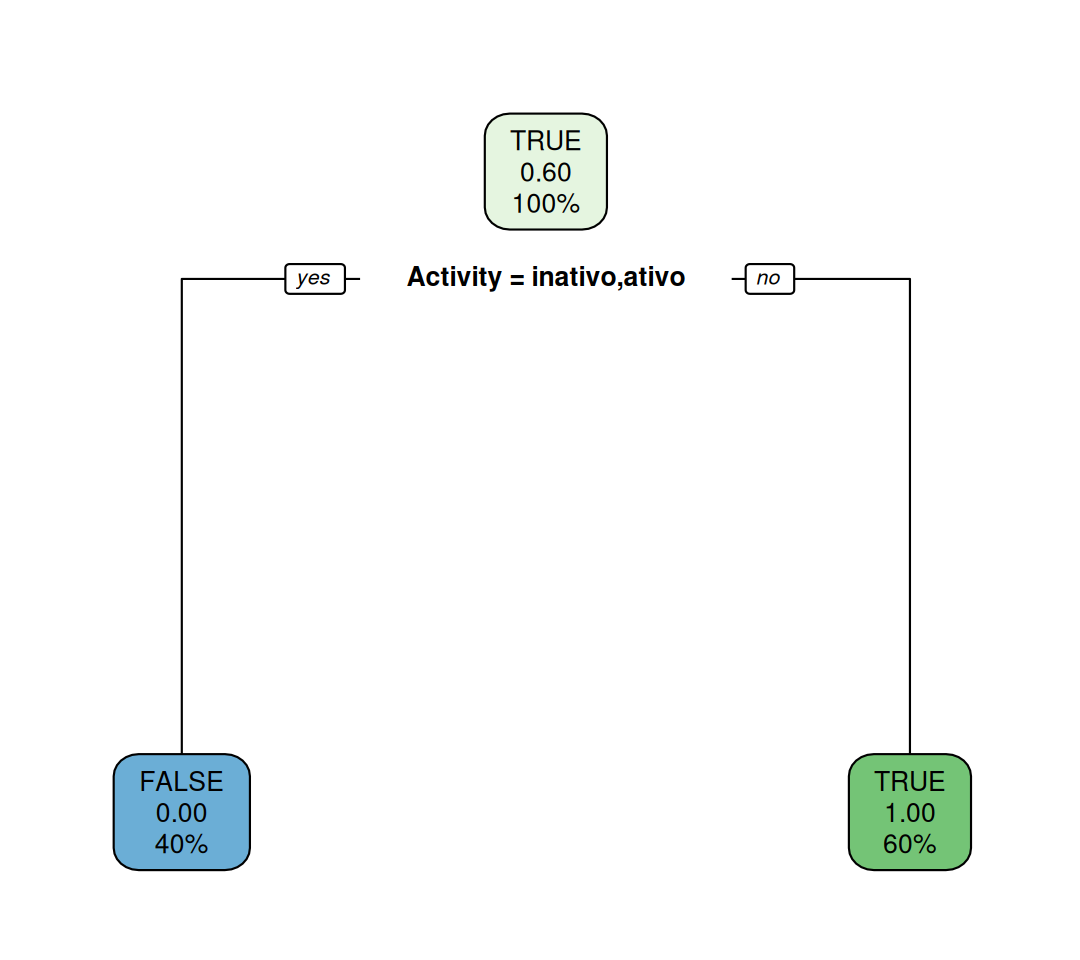

In [362]:
rpart.plot(tree.fator, cex=1.3)

Os fatores não foram definidos como ordenados (inativo-, inativo, ativo, ativo+) e por isso `rpart` testou todas possibilidades de combinação de classes. Seria interessante que a ordem fosse levada em consideração pois é uma informação que ajuda a interpretar o modelo.

In [363]:
treino <- data.frame(
    ClaimID=c(1,2,3,4,5),
    Activity=factor(x=c("ativo", "ativo+", "ativo+", "inativo", "inativo-"),
                    levels = c("inativo-", "inativo", "ativo", "ativo+"),
                    ordered=TRUE),
    Fraud=c(FALSE, TRUE, TRUE, FALSE, TRUE) )

In [364]:
tree.fator <- rpart(Fraud ~ Activity, data=treino, method="class", minsplit=2, minbucket=1)

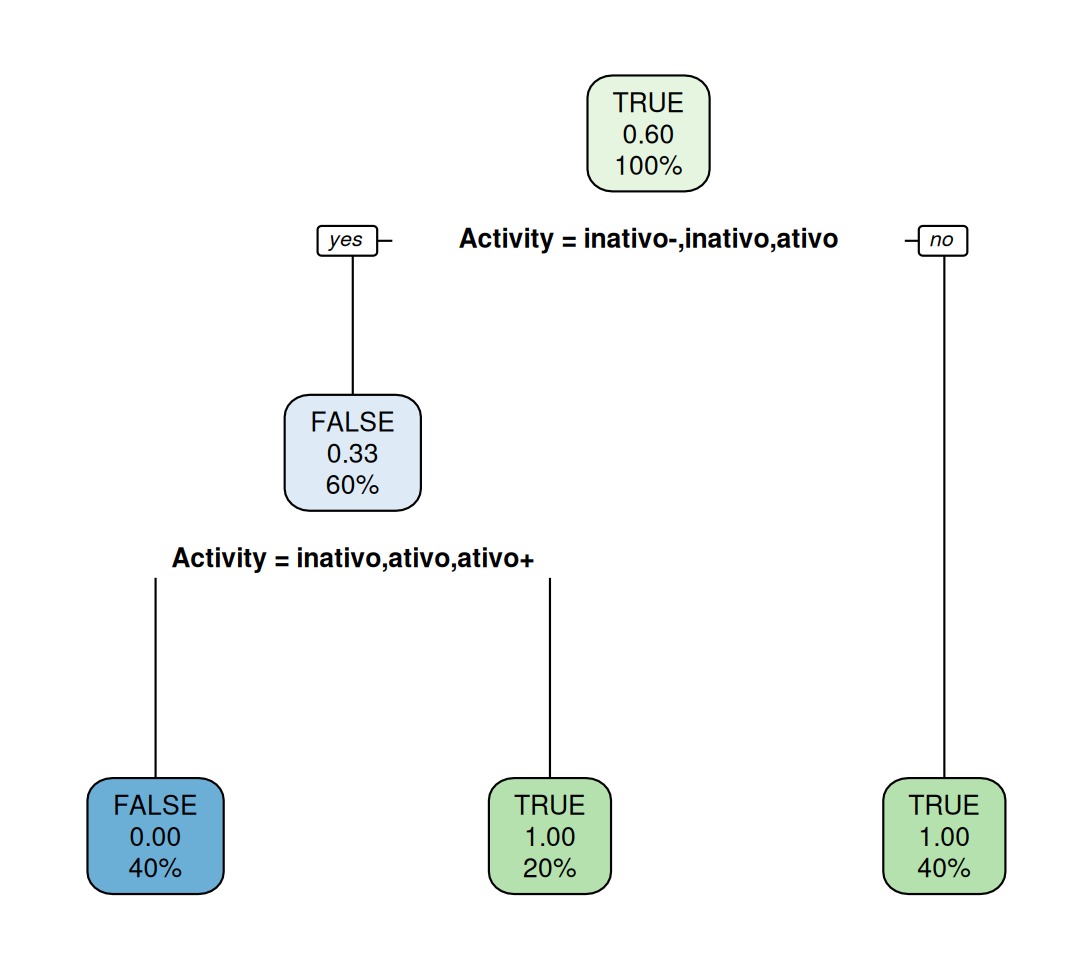

In [366]:
rpart.plot(tree.fator, cex=1.3)

#### Modelo com poda

Árvores de decisão completas tendem a sofrer de _overfiting_ pois se esforçam em ser o mais adequadas possível aos dados de treinamento, perdendo generalização. Uma solução é a poda da árvore, garantindo que não fique muito complexa ao utilizar só as principais decisões.

In [82]:
treino <- data.frame(ClaimID=1:10,
  RearEnd  = c(TRUE, TRUE, TRUE, FALSE, FALSE, FALSE, FALSE,  TRUE,  TRUE, FALSE),
  Whiplash = c(TRUE, TRUE, TRUE,  TRUE,  TRUE, FALSE, FALSE, FALSE, FALSE,  TRUE),
  Activity = factor(x=c("ativo", "ativo+", "ativo+", "inativo", "inativo-", 
                        "inativo", "inativo-", "ativo", "ativo", "ativo+"),
                    levels = c("inativo-", "inativo", "ativo", "ativo+"),
                    ordered=TRUE),
  Fraud = c(FALSE, TRUE, TRUE, FALSE, FALSE, TRUE, TRUE, FALSE, FALSE, TRUE) )

In [83]:
print(treino)

   ClaimID RearEnd Whiplash Activity Fraud
1        1    TRUE     TRUE    ativo FALSE
2        2    TRUE     TRUE   ativo+  TRUE
3        3    TRUE     TRUE   ativo+  TRUE
4        4   FALSE     TRUE  inativo FALSE
5        5   FALSE     TRUE inativo- FALSE
6        6   FALSE    FALSE  inativo  TRUE
7        7   FALSE    FALSE inativo-  TRUE
8        8    TRUE    FALSE    ativo FALSE
9        9    TRUE    FALSE    ativo FALSE
10      10   FALSE     TRUE   ativo+  TRUE


Modelo com a árvore completa:

In [84]:
tree.poda <- rpart(Fraud ~ RearEnd + Whiplash + Activity, data=treino, method="class", 
                   minsplit=2, minbucket=1, cp=-1)

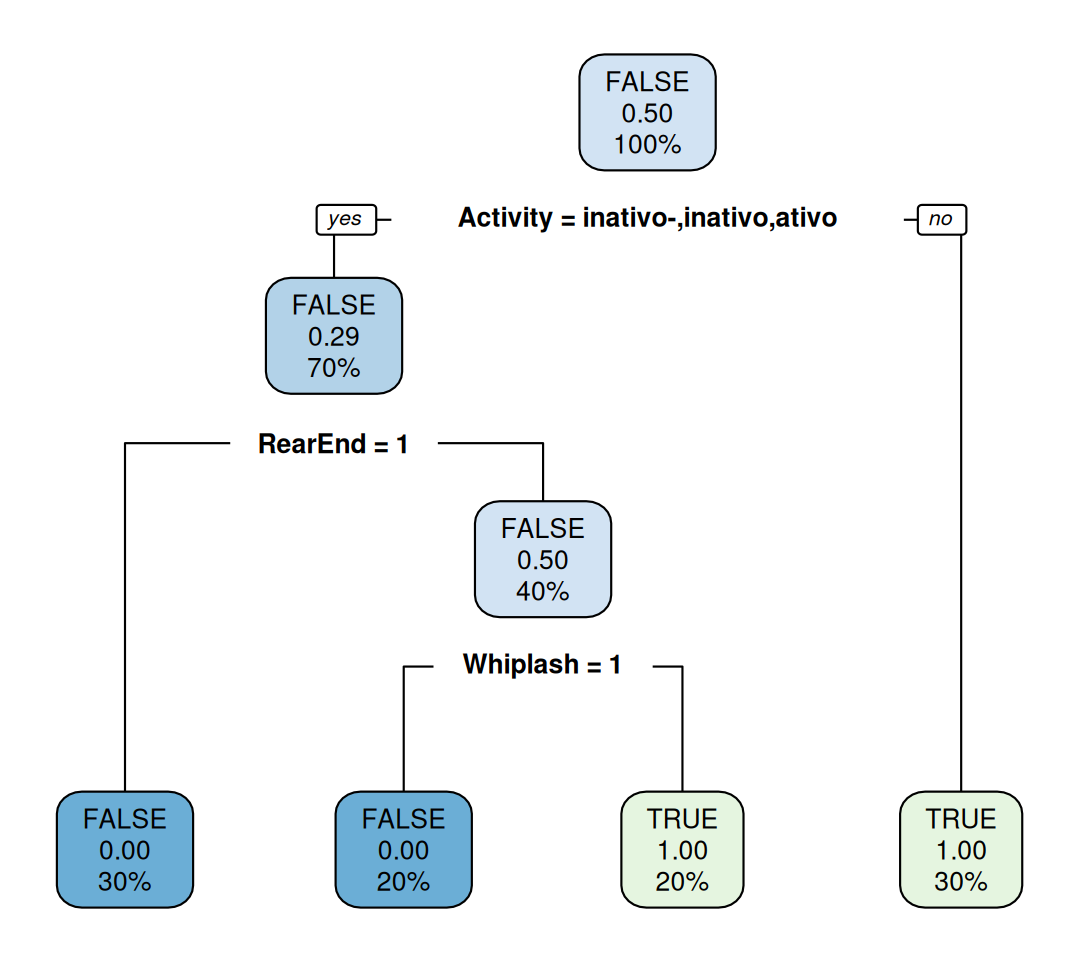

In [85]:
rpart.plot(tree.poda, cex=1.3)

A árvore corretamente classifica todos as casos. Poderia, porém, ser o caso de a árvore ser _construída_ para esses casos. Pode-se ver a importância de cada variável na construção da árvore com `variable.importance`:

In [86]:
print(tree.poda$variable.importance)

Activity Whiplash  RearEnd 
   3.000    2.000    0.857 


In [87]:
printcp(tree.poda)


Classification tree:
rpart(formula = Fraud ~ RearEnd + Whiplash + Activity, data = treino, 
    method = "class", minsplit = 2, minbucket = 1, cp = -1)

Variables actually used in tree construction:
[1] Activity RearEnd  Whiplash

Root node error: 5/10 = 0.5

n= 10 

    CP nsplit rel error xerror xstd
1  0.6      0       1.0    2.0  0.0
2  0.2      1       0.4    0.4  0.3
3 -1.0      3       0.0    0.4  0.3


O `rel error` de cada nível da árvore é a fração de observações mal classificadas no nível com relação à quantidade de observações em classes incorretas na raiz. Neste caso, com 10 observações e 5 fraudes, a raiz considerou classificar todos como fraude, acarretando um erro de 50%. A primeira divisão (é `ativo+`) gerou dois nós, um classificando como "fraude", com 3 casos de fraude (3 em 10 do total, todos 3 fraude) e outro como "não fraude" com 7 observações (7 em 10,  2 delas incorretas). A taxa de erros passou de 50% (5 erradas em 10) para 20% (2 erradas em 10), causando uma melhoria de 60% (com relação à raiz) em que há 2 erradas em 5 (40% do erro) ou 60% corretas (3 corretas das 5 erradas).

As taxas de erro da validação cruzada (_cross validation error rates_) e seus desvios padrão estão registrados na tabela como `xerror` e `xstd`, respectivamente.

Como regra, costuma-se podar uma árvore de decisão no `CP`  da menor árvore que está dentro de um desvio padrão da árvore com o menor `xerror`. Neste exemplo, o menor `xerror` é 0,40, com um desvio padrão de 0,253. Procuramos então a menor árvore com `xerror`  menor que (0,4 + 0,253) 0,653. Temos então o nível 2, com `CP` = 0,2. Podamos então a árvore com um `CP` (Parâmetro de Complexidade) ligeiramente maior que 0,2.

In [374]:
tree.podada <- prune(tree.poda, cp=0.21)

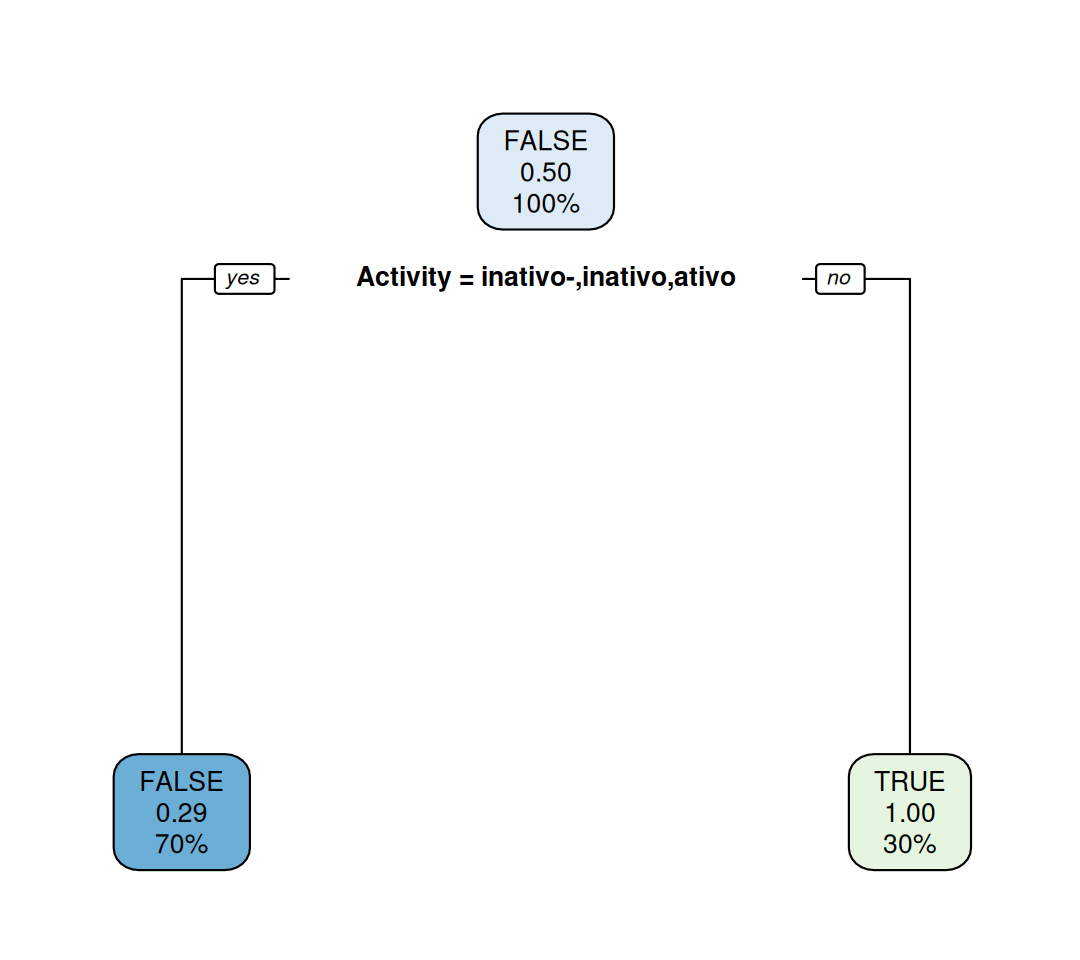

In [375]:
rpart.plot(tree.podada, cex=1.3)

Podemos usar a árvore de decisão podada para predizer propostas fraudulentas em um conjunto de dados desconhecidos.

In [376]:
teste <- data.frame(
    ClaimID=1:10,
    RearEnd  = c(FALSE, TRUE, TRUE, FALSE, FALSE, FALSE, FALSE,  TRUE,  TRUE, FALSE),
    Whiplash = c(FALSE, TRUE, TRUE,  TRUE,  TRUE, FALSE, FALSE, FALSE, FALSE,  TRUE),
    Activity = factor(
        x=c("inativo", "ativo+", "ativo+", "inativo", "inativo-",
            "inativo", "inativo-", "ativo", "ativo", "ativo+"),
    levels=c("inativo-", "inativo", "ativo", "ativo+"),
    ordered=TRUE) )

In [377]:
teste$FraudClass <- predict(tree.podada, newdata=teste, type="class")
teste$FraudProb  <- predict(tree.podada, newdata=teste, type="prob")

In [378]:
teste

ClaimID,RearEnd,Whiplash,Activity,FraudClass,FraudProb
<int>,<lgl>,<lgl>,<ord>,<fct>,"<dbl[,2]>"
1,FALSE,FALSE,inativo,FALSE,"0.714, 0.286"
2,TRUE,TRUE,ativo+,TRUE,"0.000, 1.000"
3,TRUE,TRUE,ativo+,TRUE,"0.000, 1.000"
4,FALSE,TRUE,inativo,FALSE,"0.714, 0.286"
5,FALSE,TRUE,inativo-,FALSE,"0.714, 0.286"
6,FALSE,FALSE,inativo,FALSE,"0.714, 0.286"
7,FALSE,FALSE,inativo-,FALSE,"0.714, 0.286"
8,TRUE,FALSE,ativo,FALSE,"0.714, 0.286"
9,TRUE,FALSE,ativo,FALSE,"0.714, 0.286"


### Caso 3 - Banco

[Referência](https://www.learnbymarketing.com/tutorials/rpart-decision-trees-in-r/)

[Base de árvore de decisão](https://www.learnbymarketing.com/methods/classification-and-regression-decision-trees-explained/)

Bibliotecas

In [379]:
rm(list=ls())

In [380]:
library(rpart)  # árvores de decisão
library(repr)   # representações (ajuste gráfico do jupyter)
library(caret)  # matriz de confusão
library(rpart.plot)
library(RColorBrewer)

In [381]:
grafdim <- function(x=11, y=9) { options(repr.plot.width=x, repr.plot.height=y) }
grafdim()

Preparação do ambiente

In [382]:
set.seed(997)

#### Dados originais

O banco de dados utilizado está em `bank.Zip` no repositório em [Bank+Marketing]( http://archive.ics.uci.edu/ml/datasets/Bank+Marketing).

In [383]:
orig <- read.csv(unzip("/home/max/ref/d/dataset/bank_marketing.zip","bank-full.csv"),
                 sep=";", header=TRUE)
file.remove("bank-full.csv")

[1] TRUE

In [384]:
head(orig)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
,<int>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<int>,<int>,<int>,<chr>,<chr>
1,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
2,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
3,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
4,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
5,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
6,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no


In [385]:
str(orig)

'data.frame':	45211 obs. of  17 variables:
 $ age      : int  58 44 33 47 33 35 28 42 58 43 ...
 $ job      : chr  "management" "technician" "entrepreneur" "blue-collar" ...
 $ marital  : chr  "married" "single" "married" "married" ...
 $ education: chr  "tertiary" "secondary" "secondary" "unknown" ...
 $ default  : chr  "no" "no" "no" "no" ...
 $ balance  : int  2143 29 2 1506 1 231 447 2 121 593 ...
 $ housing  : chr  "yes" "yes" "yes" "yes" ...
 $ loan     : chr  "no" "no" "yes" "no" ...
 $ contact  : chr  "unknown" "unknown" "unknown" "unknown" ...
 $ day      : int  5 5 5 5 5 5 5 5 5 5 ...
 $ month    : chr  "may" "may" "may" "may" ...
 $ duration : int  261 151 76 92 198 139 217 380 50 55 ...
 $ campaign : int  1 1 1 1 1 1 1 1 1 1 ...
 $ pdays    : int  -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 ...
 $ previous : int  0 0 0 0 0 0 0 0 0 0 ...
 $ poutcome : chr  "unknown" "unknown" "unknown" "unknown" ...
 $ y        : chr  "no" "no" "no" "no" ...


In [386]:
print(summary(factor(orig$job)))

       admin.   blue-collar  entrepreneur     housemaid    management 
         5171          9732          1487          1240          9458 
      retired self-employed      services       student    technician 
         2264          1579          4154           938          7597 
   unemployed       unknown 
         1303           288 


In [387]:
orig$job <- factor(orig$job)

In [388]:
print(summary(factor(orig$contact)))

 cellular telephone   unknown 
    29285      2906     13020 


In [389]:
orig$contact <- factor(orig$contact)

In [390]:
orig$contrata <- factor(orig$y)

In [391]:
orig$y <- NULL

In [392]:
print(summary(factor(orig$marital)))

divorced  married   single 
    5207    27214    12790 


In [393]:
orig$marital <- factor(orig$marital)

In [394]:
print(summary(factor(orig$education)))

  primary secondary  tertiary   unknown 
     6851     23202     13301      1857 


In [395]:
orig$education <- factor(orig$education, 
                         levels=c("unknown", "primary", "secondary", "tertiary"), 
                         ordered=TRUE)

In [396]:
orig$housing <- factor(orig$housing)

In [397]:
orig$default <- factor(orig$default)

In [398]:
orig$loan    <- factor(orig$loan)

In [399]:
x <- orig$month
x[x == "jan"] <- 1
x[x == "feb"] <- 2
x[x == "mar"] <- 3
x[x == "apr"] <- 4
x[x == "may"] <- 5
x[x == "jun"] <- 6
x[x == "jul"] <- 7
x[x == "aug"] <- 8
x[x == "sep"] <- 9
x[x == "oct"] <- 10
x[x == "nov"] <- 11
x[x == "dec"] <- 12

In [400]:
x <- as.integer(x)

In [401]:
x <- factor(x)

In [402]:
orig$month <- x

In [403]:
orig$poutcome <- factor(orig$poutcome)

In [404]:
summary(orig)

      age                job           marital          education    
 Min.   :18.0   blue-collar:9732   divorced: 5207   unknown  : 1857  
 1st Qu.:33.0   management :9458   married :27214   primary  : 6851  
 Median :39.0   technician :7597   single  :12790   secondary:23202  
 Mean   :40.9   admin.     :5171                    tertiary :13301  
 3rd Qu.:48.0   services   :4154                                     
 Max.   :95.0   retired    :2264                                     
                (Other)    :6835                                     
 default        balance       housing      loan            contact     
 no :44396   Min.   : -8019   no :20081   no :37967   cellular :29285  
 yes:  815   1st Qu.:    72   yes:25130   yes: 7244   telephone: 2906  
             Median :   448                           unknown  :13020  
             Mean   :  1362                                            
             3rd Qu.:  1428                                            
        

In [405]:
bank <- orig

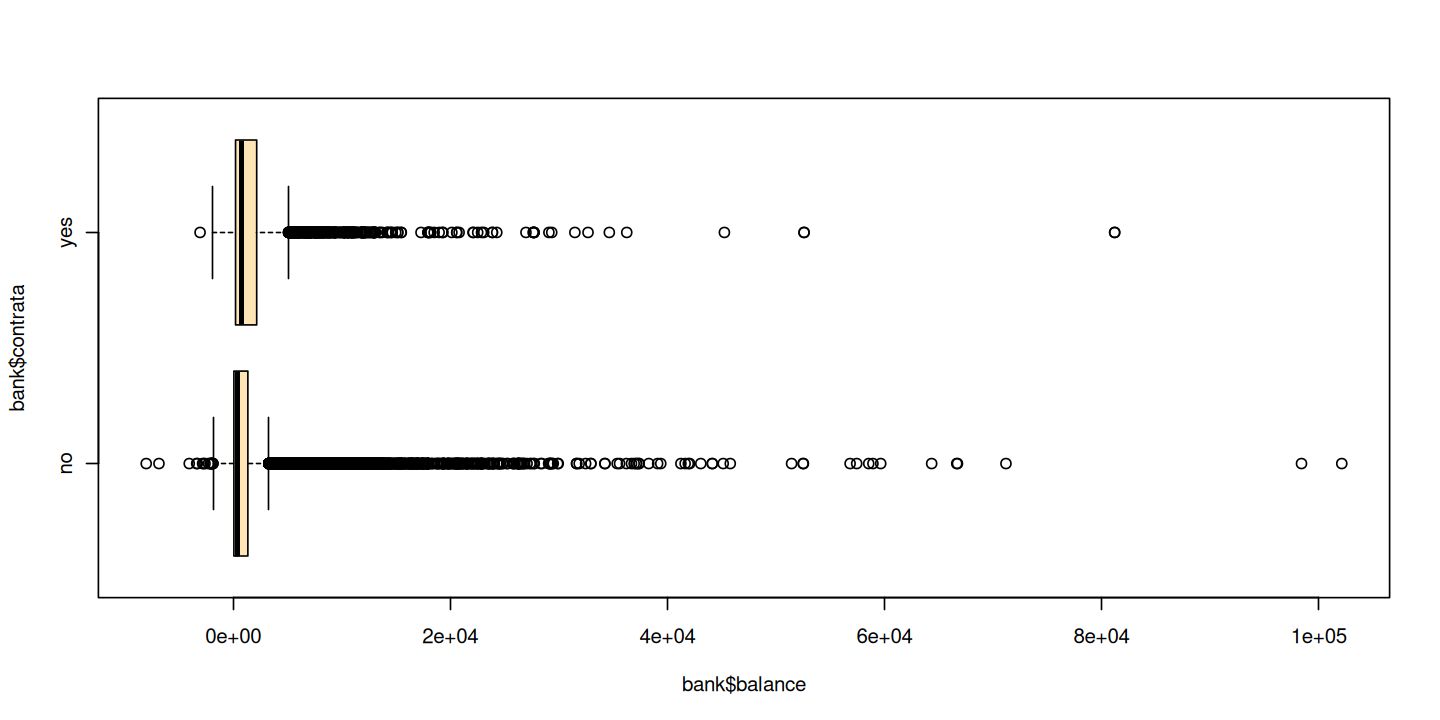

In [406]:
grafdim(12,6)
boxplot(bank$balance ~ bank$contrata, col="moccasin", horizontal=TRUE)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  -8019    -422    -230    -318     -93      -1 

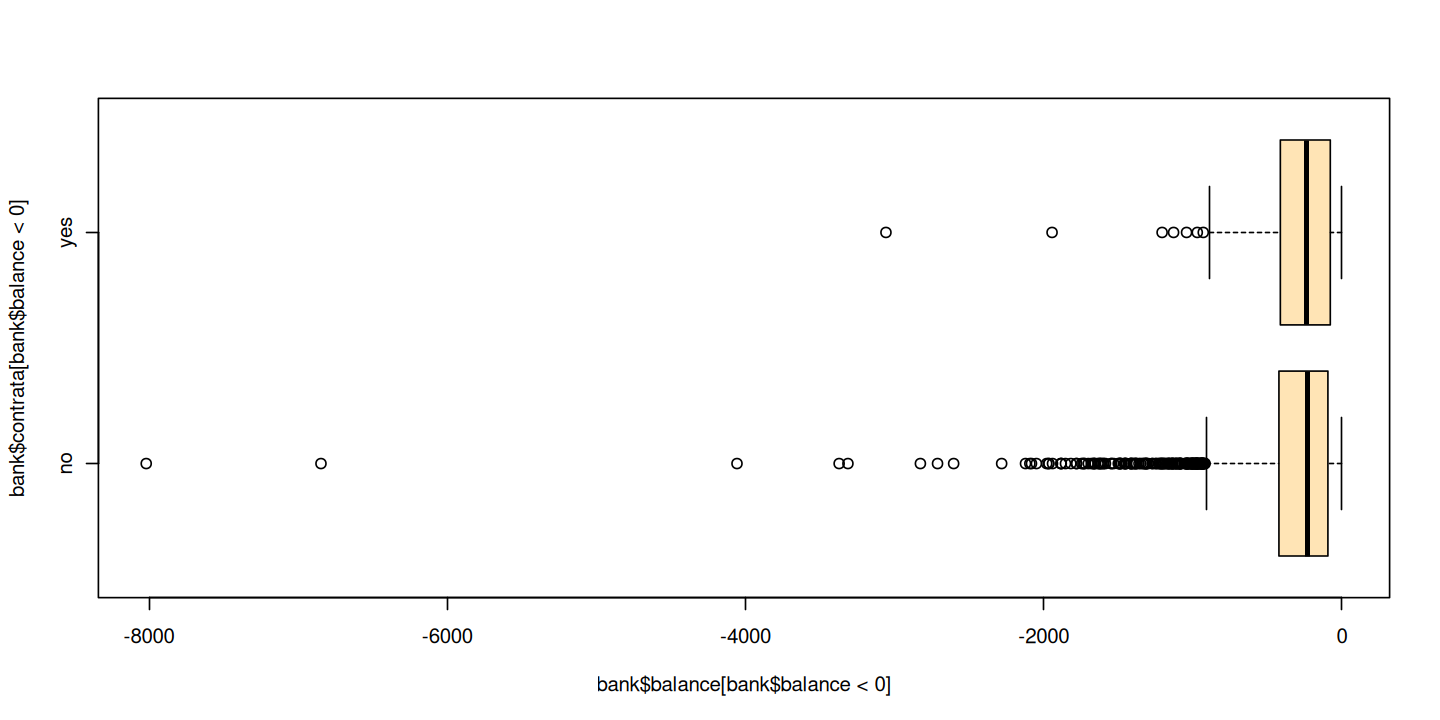

In [407]:
summary(bank$balance[bank$balance < 0]) 
boxplot(bank$balance[bank$balance < 0] ~ bank$contrata[bank$balance < 0], 
        col="moccasin", horizontal=TRUE)

In [408]:
summary(bank)

      age                job           marital          education    
 Min.   :18.0   blue-collar:9732   divorced: 5207   unknown  : 1857  
 1st Qu.:33.0   management :9458   married :27214   primary  : 6851  
 Median :39.0   technician :7597   single  :12790   secondary:23202  
 Mean   :40.9   admin.     :5171                    tertiary :13301  
 3rd Qu.:48.0   services   :4154                                     
 Max.   :95.0   retired    :2264                                     
                (Other)    :6835                                     
 default        balance       housing      loan            contact     
 no :44396   Min.   : -8019   no :20081   no :37967   cellular :29285  
 yes:  815   1st Qu.:    72   yes:25130   yes: 7244   telephone: 2906  
             Median :   448                           unknown  :13020  
             Mean   :  1362                                            
             3rd Qu.:  1428                                            
        

In [409]:
save(data="bank", file="bank.RData")

In [410]:
ls()

[1] "bank"    "grafdim" "orig"    "x"

#### Dados processados

In [411]:
load("bank.RData")

In [412]:
ls()

[1] "bank"    "grafdim" "orig"    "x"

In [413]:
summary(bank)

      age                job           marital          education    
 Min.   :18.0   blue-collar:9732   divorced: 5207   unknown  : 1857  
 1st Qu.:33.0   management :9458   married :27214   primary  : 6851  
 Median :39.0   technician :7597   single  :12790   secondary:23202  
 Mean   :40.9   admin.     :5171                    tertiary :13301  
 3rd Qu.:48.0   services   :4154                                     
 Max.   :95.0   retired    :2264                                     
                (Other)    :6835                                     
 default        balance       housing      loan            contact     
 no :44396   Min.   : -8019   no :20081   no :37967   cellular :29285  
 yes:  815   1st Qu.:    72   yes:25130   yes: 7244   telephone: 2906  
             Median :   448                           unknown  :13020  
             Mean   :  1362                                            
             3rd Qu.:  1428                                            
        

#### Separação dos conjuntos de _treino_, _validação_ e _teste_

In [414]:
(num_obs    <- nrow(bank))
tx_teste    <- 0.15
tx_valida   <- 0.15
(num_teste  <- trunc(num_obs * tx_teste))
(num_valida <- trunc(num_obs * tx_valida))
(num_treino <- num_obs - num_teste - num_valida)

[1] 45211

[1] 6781

[1] 6781

[1] 31649

In [415]:
set.seed(997)

In [416]:
bank_treino <- bank
amostra  <- sample(1:num_obs, num_teste, replace=FALSE)
bank_teste  <- bank_treino[ amostra, ]
bank_treino <- bank_treino[-amostra, ]
amostra  <- sample(1:(num_obs - num_teste), num_valida, replace=FALSE)
bank_valida <- bank_treino[ amostra, ]
bank_treino <- bank_treino[-amostra, ]
head(bank_treino)
head(bank_valida)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,contrata
,<int>,<fct>,<fct>,<ord>,<fct>,<int>,<fct>,<fct>,<fct>,<int>,<fct>,<int>,<int>,<int>,<int>,<fct>,<fct>
1,58,management,married,tertiary,no,2143,yes,no,unknown,5,5,261,1,-1,0,unknown,no
3,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,5,76,1,-1,0,unknown,no
4,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,5,92,1,-1,0,unknown,no
6,35,management,married,tertiary,no,231,yes,no,unknown,5,5,139,1,-1,0,unknown,no
7,28,management,single,tertiary,no,447,yes,yes,unknown,5,5,217,1,-1,0,unknown,no
8,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,5,380,1,-1,0,unknown,no


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,contrata
,<int>,<fct>,<fct>,<ord>,<fct>,<int>,<fct>,<fct>,<fct>,<int>,<fct>,<int>,<int>,<int>,<int>,<fct>,<fct>
37094,47,housemaid,single,primary,no,2785,yes,no,cellular,13,5,570,1,-1,0,unknown,yes
11572,46,blue-collar,married,unknown,no,626,yes,no,unknown,19,6,177,2,-1,0,unknown,no
24018,37,admin.,married,secondary,no,373,no,no,cellular,29,8,98,10,-1,0,unknown,no
20354,56,services,divorced,secondary,no,476,no,no,cellular,11,8,67,7,-1,0,unknown,no
36192,41,services,married,unknown,no,88,yes,no,cellular,11,5,105,1,336,2,failure,no
5803,40,technician,married,secondary,no,-396,yes,no,unknown,26,5,127,1,-1,0,unknown,no


A proporção de positivos deve ser próxima nos três conjuntos.

In [417]:
(sum(bank_treino$contrata == "yes") / nrow(bank_treino))
(sum(bank_valida$contrata == "yes") / nrow(bank_valida))
(sum(bank_teste$contrata == "yes")  / nrow(bank_teste))

[1] 0.116

[1] 0.123

[1] 0.117

A proporção de positivos ficou próxima de 12% nos três conjuntos, não há indício de favorecimento em algum conjunto. Porém a classe de estudo é bastante desbalanceada; alguma técnica de balanceamento deve ser utilizada.

#### Dados separados em _treino_, _validação_ e _teste_

In [418]:
save(bank_treino, bank_valida, bank_teste, file="bank_treino_valida_teste.RData")

In [419]:
load("bank_treino_valida_teste.RData")
ls()

[1] "amostra"     "bank"        "bank_teste"  "bank_treino" "bank_valida"
 [6] "grafdim"     "num_obs"     "num_teste"   "num_treino"  "num_valida" 
[11] "orig"        "tx_teste"    "tx_valida"   "x"

#### Modelo base de comparação (_baseline_)

In [420]:
summary(bank_treino)

      age                job           marital          education    
 Min.   :18.0   blue-collar:6830   divorced: 3652   unknown  : 1280  
 1st Qu.:33.0   management :6590   married :19060   primary  : 4820  
 Median :39.0   technician :5353   single  : 8937   secondary:16210  
 Mean   :40.9   admin.     :3650                    tertiary : 9339  
 3rd Qu.:48.0   services   :2891                                     
 Max.   :95.0   retired    :1554                                     
                (Other)    :4781                                     
 default        balance       housing      loan            contact     
 no :31068   Min.   : -8019   no :13985   no :26479   cellular :20490  
 yes:  581   1st Qu.:    72   yes:17664   yes: 5170   telephone: 2007  
             Median :   445                           unknown  : 9152  
             Mean   :  1341                                            
             3rd Qu.:  1403                                            
        

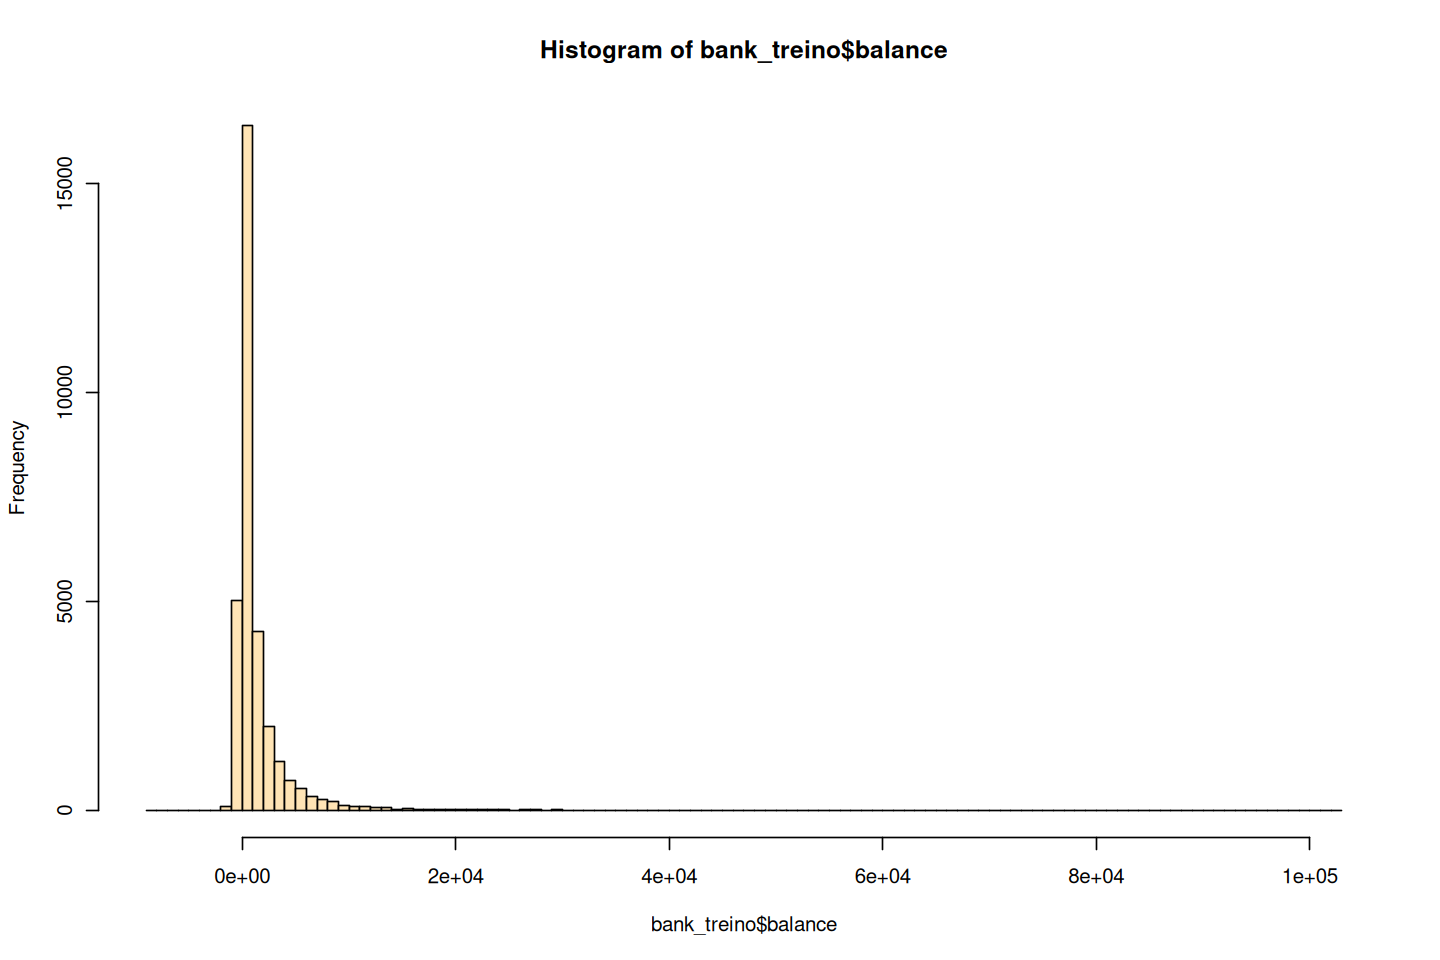

In [421]:
grafdim(12,8)
hist(bank_treino$balance, breaks=100, col="moccasin")

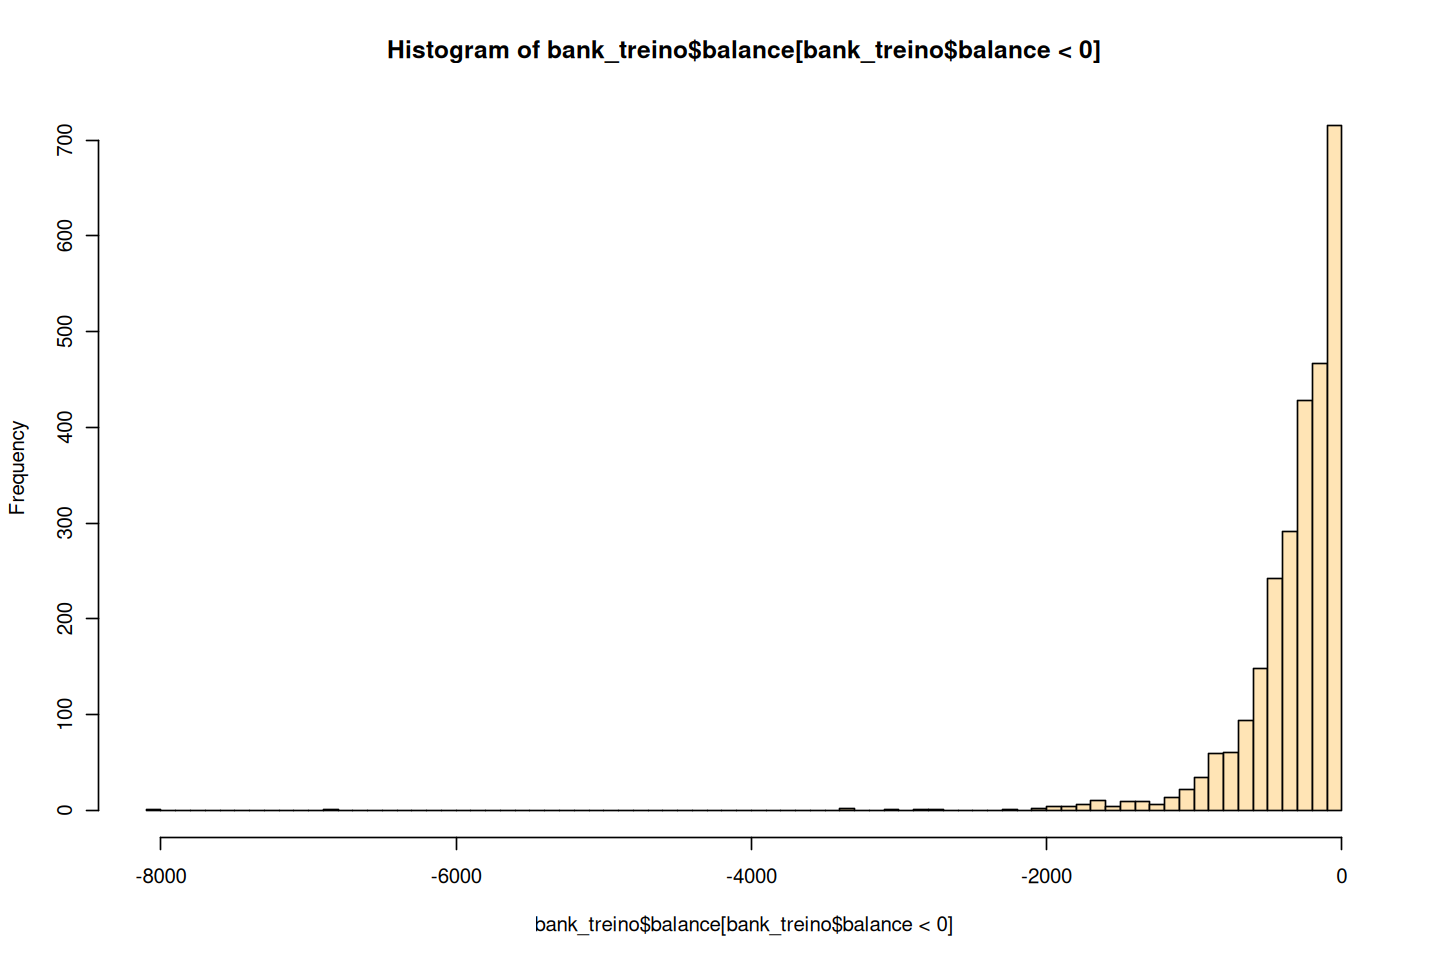

In [422]:
hist(bank_treino$balance[bank_treino$balance < 0], breaks=100, col="moccasin")

In [423]:
(min_balance <-  min(c(bank_treino$balance, bank_teste$balance, bank_valida$balance) - 1))

[1] -8020

In [424]:
bal_treino <- log(bank_treino$balance - min_balance) - log(-min_balance)
bal_teste  <- log(bank_teste$balance  - min_balance) - log(-min_balance)
bal_valida <- log(bank_valida$balance - min_balance) - log(-min_balance)

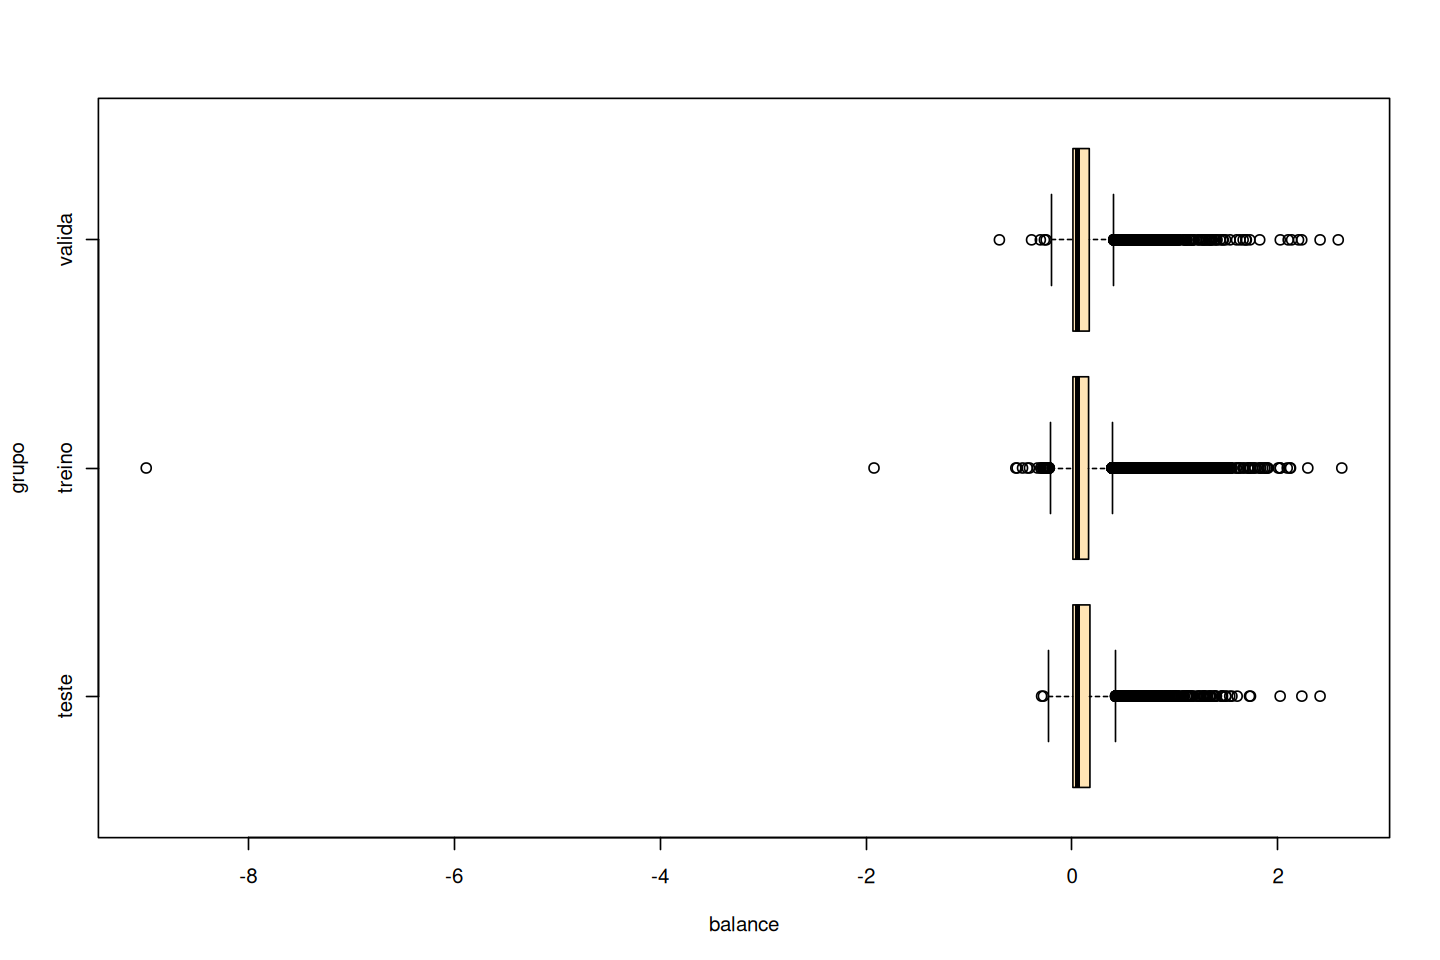

In [425]:
# dt <- data.frame(bal_treino, rep(length(bal_treino), "treino"))
boxplot(balance ~ grupo, data.frame(balance=c(bal_treino, bal_valida, bal_teste), 
                 grupo=c(rep("treino",length(bal_treino)), rep("valida",length(bal_valida)),
                   rep("teste",length(bal_teste)))), horizontal=TRUE, col="moccasin")

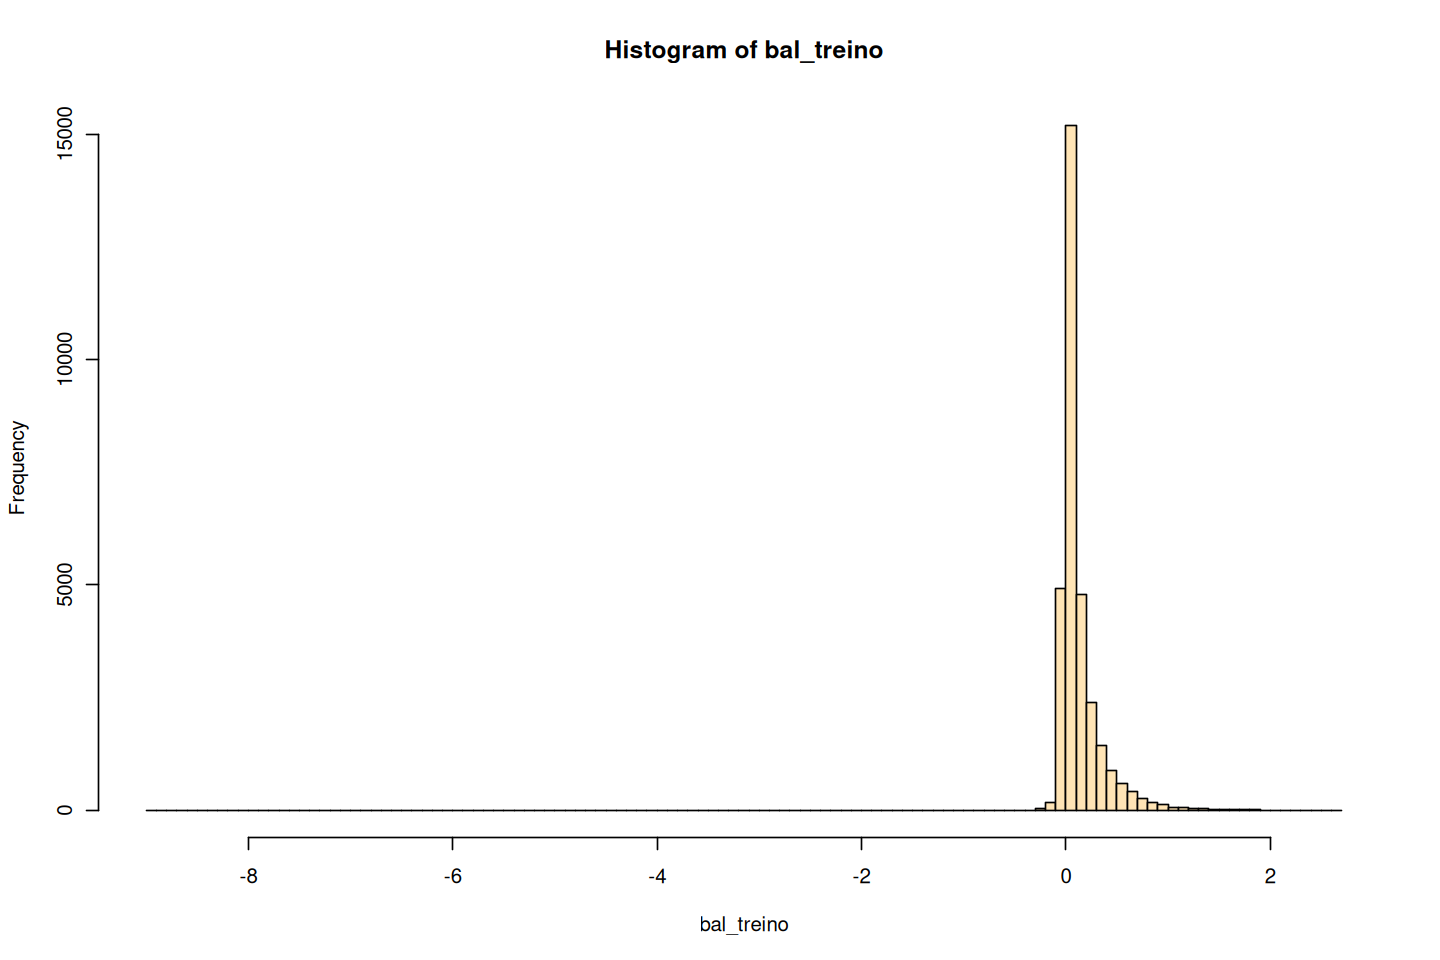

In [426]:
hist(bal_treino, breaks=100, col="moccasin")

In [427]:
bank_treino$balance <- bal_treino
bank_valida$balance <- bal_valida
bank_teste$balance  <- bal_teste

In [428]:
modelo_base <- rpart(contrata ~ . , data=bank_treino, 
                     method="class",
                     minsplit=20, minbucket=7, maxdepth=30)

In [429]:
printcp(modelo_base)


Classification tree:
rpart(formula = contrata ~ ., data = bank_treino, method = "class", 
    minsplit = 20, minbucket = 7, maxdepth = 30)

Variables actually used in tree construction:
[1] duration poutcome

Root node error: 3666/31649 = 0.1

n= 31649 

    CP nsplit rel error xerror xstd
1 0.04      0       1.0    1.0 0.02
2 0.02      3       0.9    0.9 0.01
3 0.02      4       0.9    0.9 0.01
4 0.01      5       0.8    0.9 0.01


In [240]:
print(modelo_base$variable.importance)

duration poutcome  contact    pdays previous  balance    month campaign 
941.6948 596.5276   1.2025   0.7215   0.4810   0.3810   0.1405   0.0702 


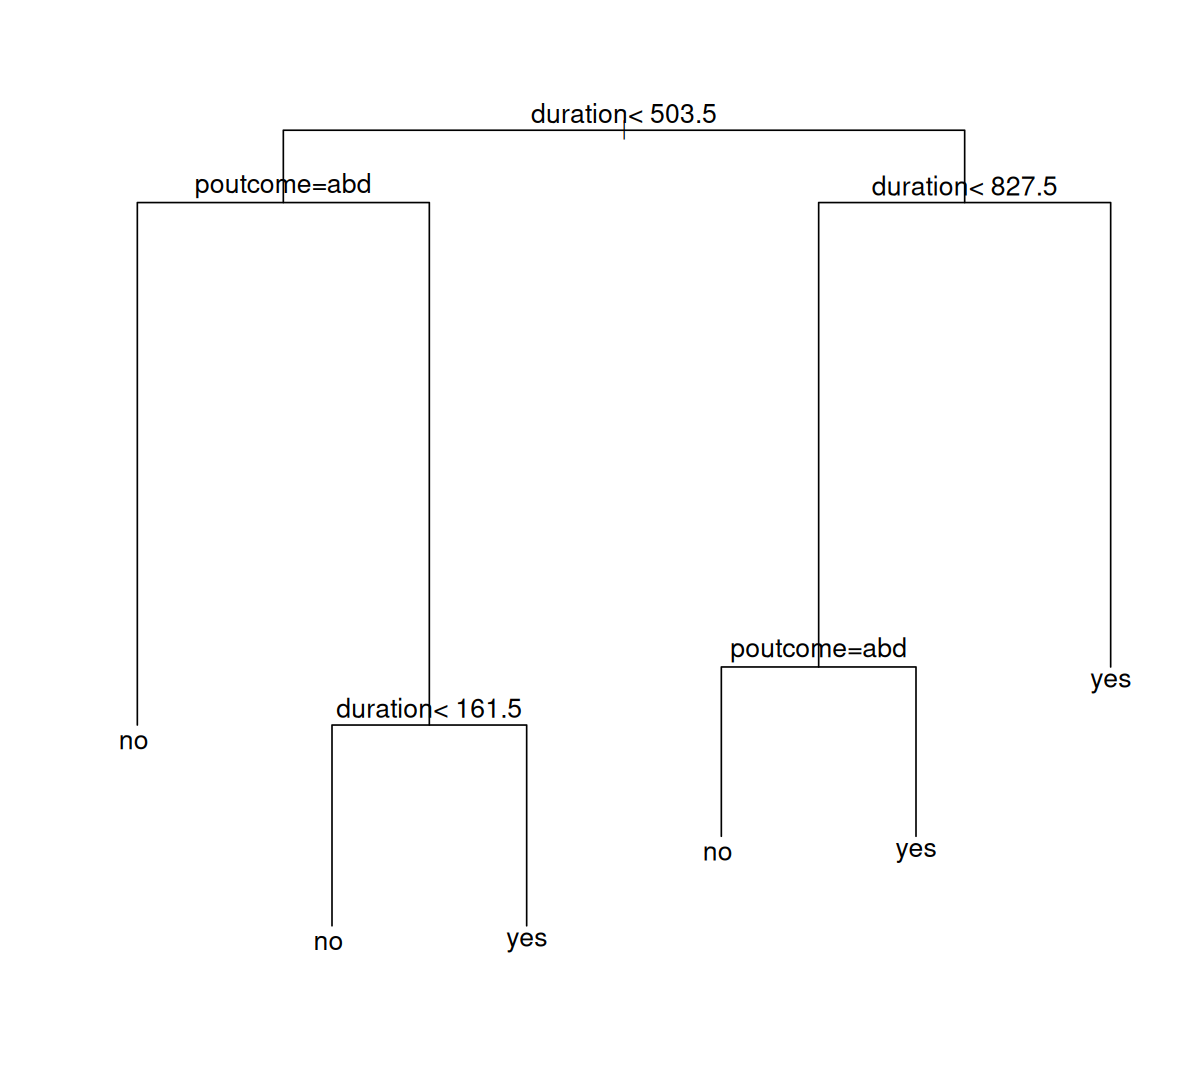

In [430]:
grafdim(10,9)
plot(modelo_base)
text(modelo_base, cex=1.3, xpd=TRUE)

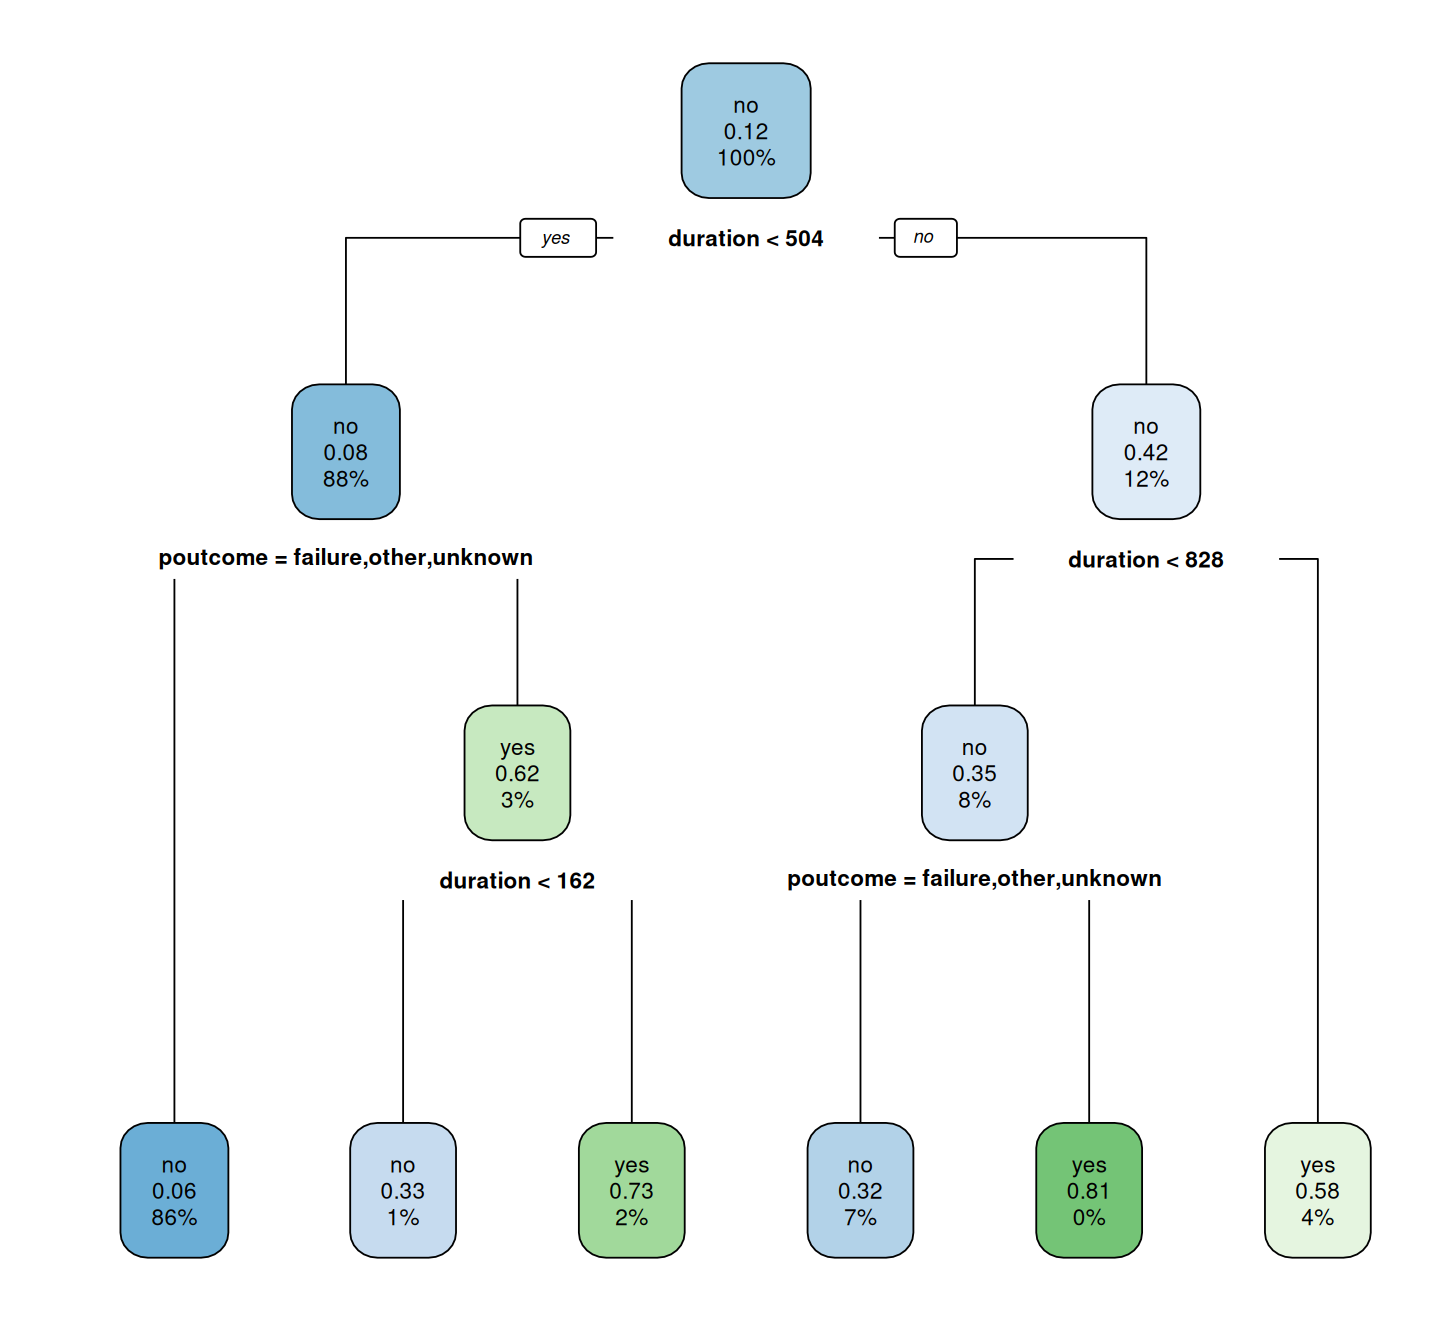

In [431]:
grafdim(12,11)
rpart.plot(modelo_base, cex=1.1)

In [432]:
predito_base <- predict(modelo_base, bank_valida, type="class")

In [433]:
print(head(predito_base,12))

37094 11572 24018 20354 36192  5803 17978 31118  1112 21636  8384 38061 
   no    no    no    no    no    no    no   yes    no    no   yes    no 
Levels: no yes


In [434]:
table(predito_base, classe=bank_valida$contrata)

            classe
predito_base   no  yes
         no  5819  542
         yes  131  289

In [435]:
(matconf_base <- confusionMatrix(predito_base, bank_valida$contrata, positive="yes"))

Confusion Matrix and Statistics

          Reference
Prediction   no  yes
       no  5819  542
       yes  131  289
                                        
               Accuracy : 0.901         
                 95% CI : (0.893, 0.908)
    No Information Rate : 0.877         
    P-Value [Acc > NIR] : 9.8e-10       
                                        
                  Kappa : 0.414         
                                        
 Mcnemar's Test P-Value : < 2e-16       
                                        
            Sensitivity : 0.3478        
            Specificity : 0.9780        
         Pos Pred Value : 0.6881        
         Neg Pred Value : 0.9148        
             Prevalence : 0.1225        
         Detection Rate : 0.0426        
   Detection Prevalence : 0.0619        
      Balanced Accuracy : 0.6629        
                                        
       'Positive' Class : yes           
                                        

In [436]:
(accbal_base <- matconf_base$byClass["Balanced Accuracy"])

Balanced Accuracy 
            0.663

In [437]:
tabela <- as.data.frame(matconf_base$table)
tabela$Reference <- factor(tabela$Reference, levels=rev(levels(tabela$Reference)))
tabela

Prediction,Reference,Freq
<fct>,<fct>,<int>
no,no,5819
yes,no,131
no,yes,542
yes,yes,289


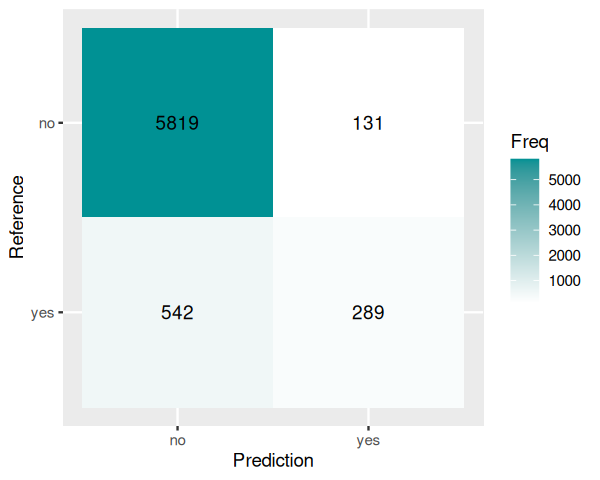

In [440]:
grafdim(5,4)
ggplot(tabela, aes(Prediction, Reference, fill=Freq)) +
        geom_tile() + geom_text(aes(label=Freq)) +
        scale_fill_gradient(low="white", high="#009194") +
        labs(x="Prediction", y="Reference")

Muito caso positivo perdido por falso negativo.

#### Modelo com ponderação

Construção do vetor com os pesos. No caso, o peso de um caso é a proporção de casos da outra classe.

In [441]:
pesos <- numeric(nrow(bank_treino))
(qtd_yes <- sum(bank_treino$contrata == "yes"))
(qtd_no  <- sum(bank_treino$contrata == "no"))
(qtd <- qtd_yes + qtd_no)
nrow(bank_treino)
(py   <- qtd_yes / qtd) 
(pn   <- qtd_no  / qtd)
pesos[bank_treino$contrata == "yes"] <- pn # peso de "sim" é a proporção de "não" e vice-versa
pesos[bank_treino$contrata == "no"]  <- py
print(head(pesos))

[1] 3666

[1] 27983

[1] 31649

[1] 31649

[1] 0.116

[1] 0.884

[1] 0.116 0.116 0.116 0.116 0.116 0.116


In [442]:
modelo_peso <- rpart(contrata ~ . , data=bank_treino, 
                     method="class",
                     weight=pesos,
                     minsplit=20, minbucket=7, maxdepth=30)

In [443]:
printcp(modelo_peso)


Classification tree:
rpart(formula = contrata ~ ., data = bank_treino, weights = pesos, 
    method = "class", minsplit = 20, minbucket = 7, maxdepth = 30)

Variables actually used in tree construction:
[1] contact  day      duration housing  month    poutcome

Root node error: 3241/31649 = 0.1

n= 31649 

    CP nsplit rel error xerror xstd
1 0.44      0       1.0    1.0 0.01
2 0.04      1       0.6    0.6 0.01
3 0.02      3       0.5    0.5 0.01
4 0.02      6       0.4    0.4 0.01
5 0.01      9       0.4    0.4 0.01
6 0.01     11       0.3    0.4 0.01


In [444]:
print(modelo_peso$variable.importance)

duration    month poutcome  contact  housing      day    pdays previous 
  845.12   315.97   192.34   165.96    47.46    24.67    21.59    17.68 
campaign      age      job  balance 
   10.76     9.16     6.26     1.58 


Como regra, costuma-se podar uma árvore de decisão no CP da menor árvore que está dentro de um desvio padrão da árvore com o menor xerror. Neste exemplo, o menor xerror é 0,40, com um desvio padrão de 0,253. Procuramos então a menor árvore com xerror menor que (0,4 + 0,253) 0,653. Temos então o nível 2, com CP = 0,2. Podamos então a árvore com um CP (Parâmetro de Complexidade) ligeiramente maior que 0,2.

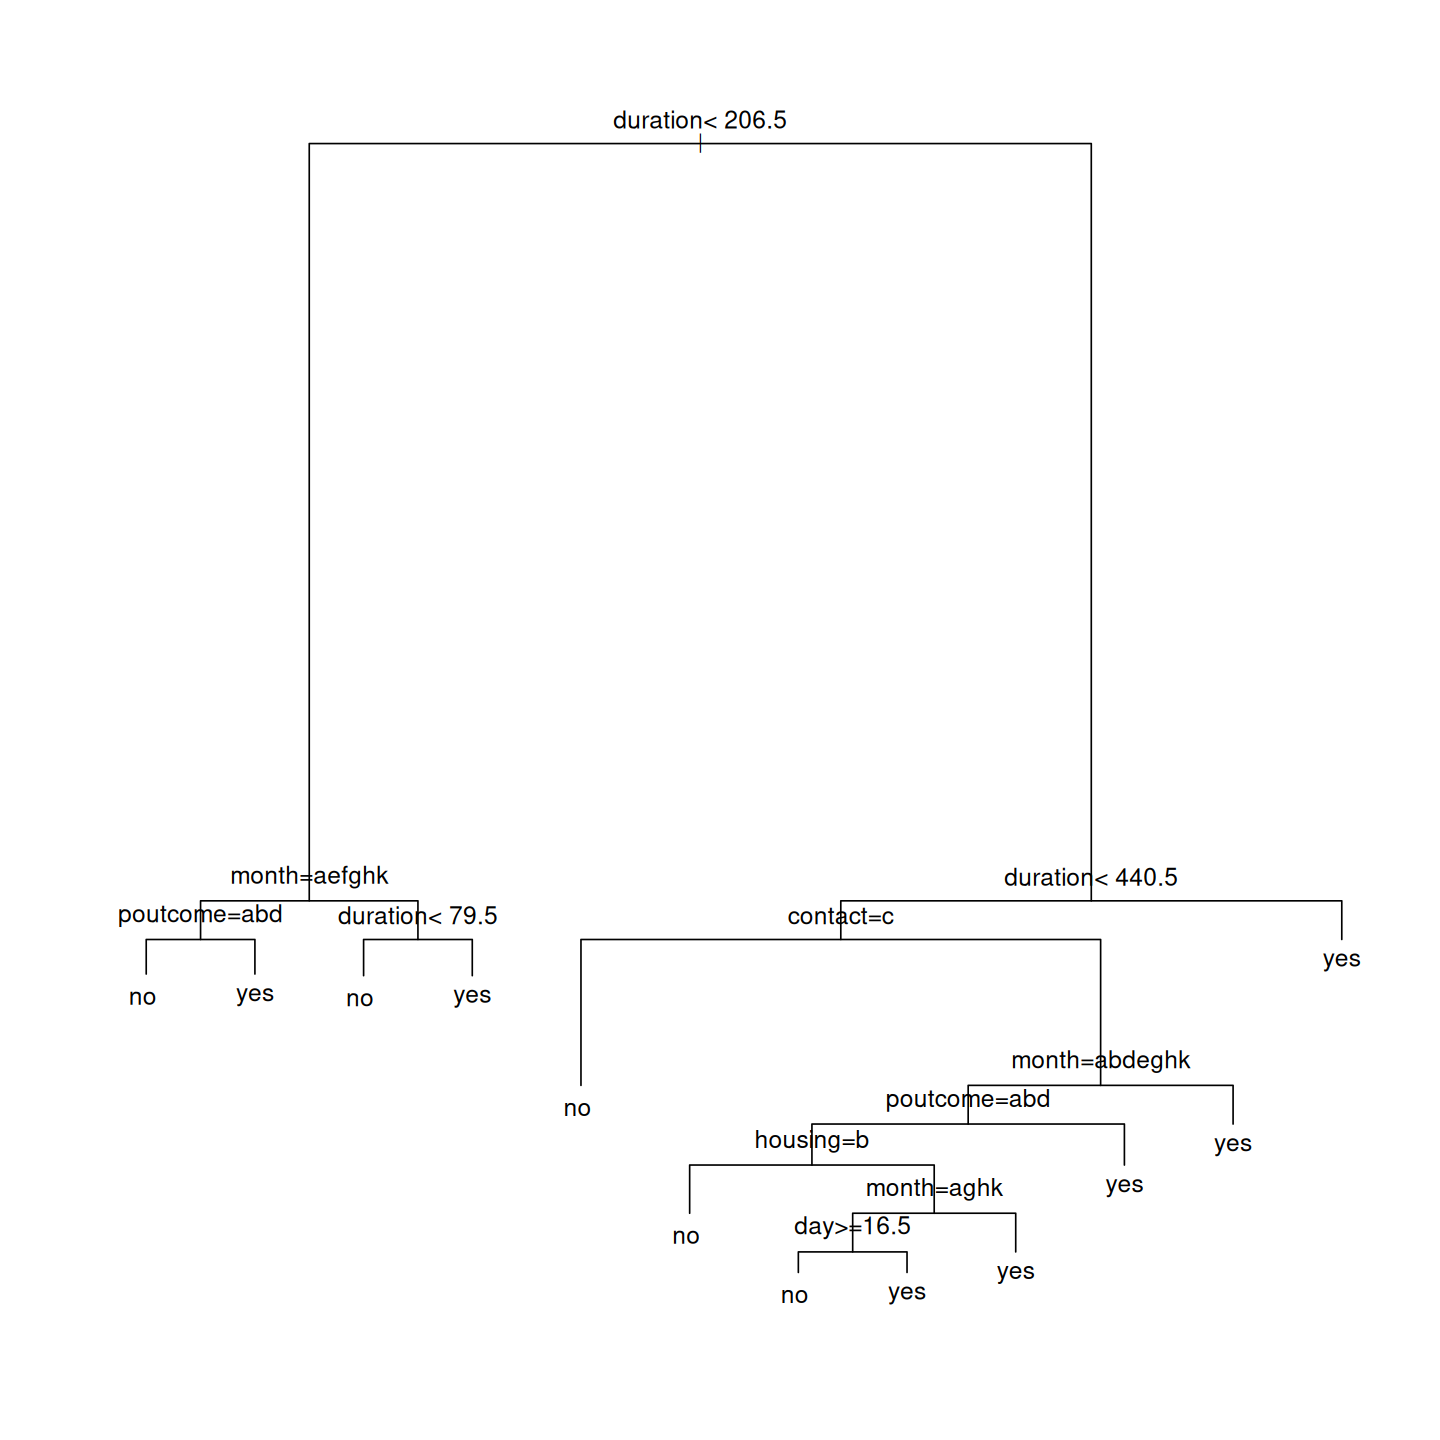

In [445]:
grafdim(12,12)
plot(modelo_peso)
text(modelo_peso, cex=1.2, xpd=TRUE)

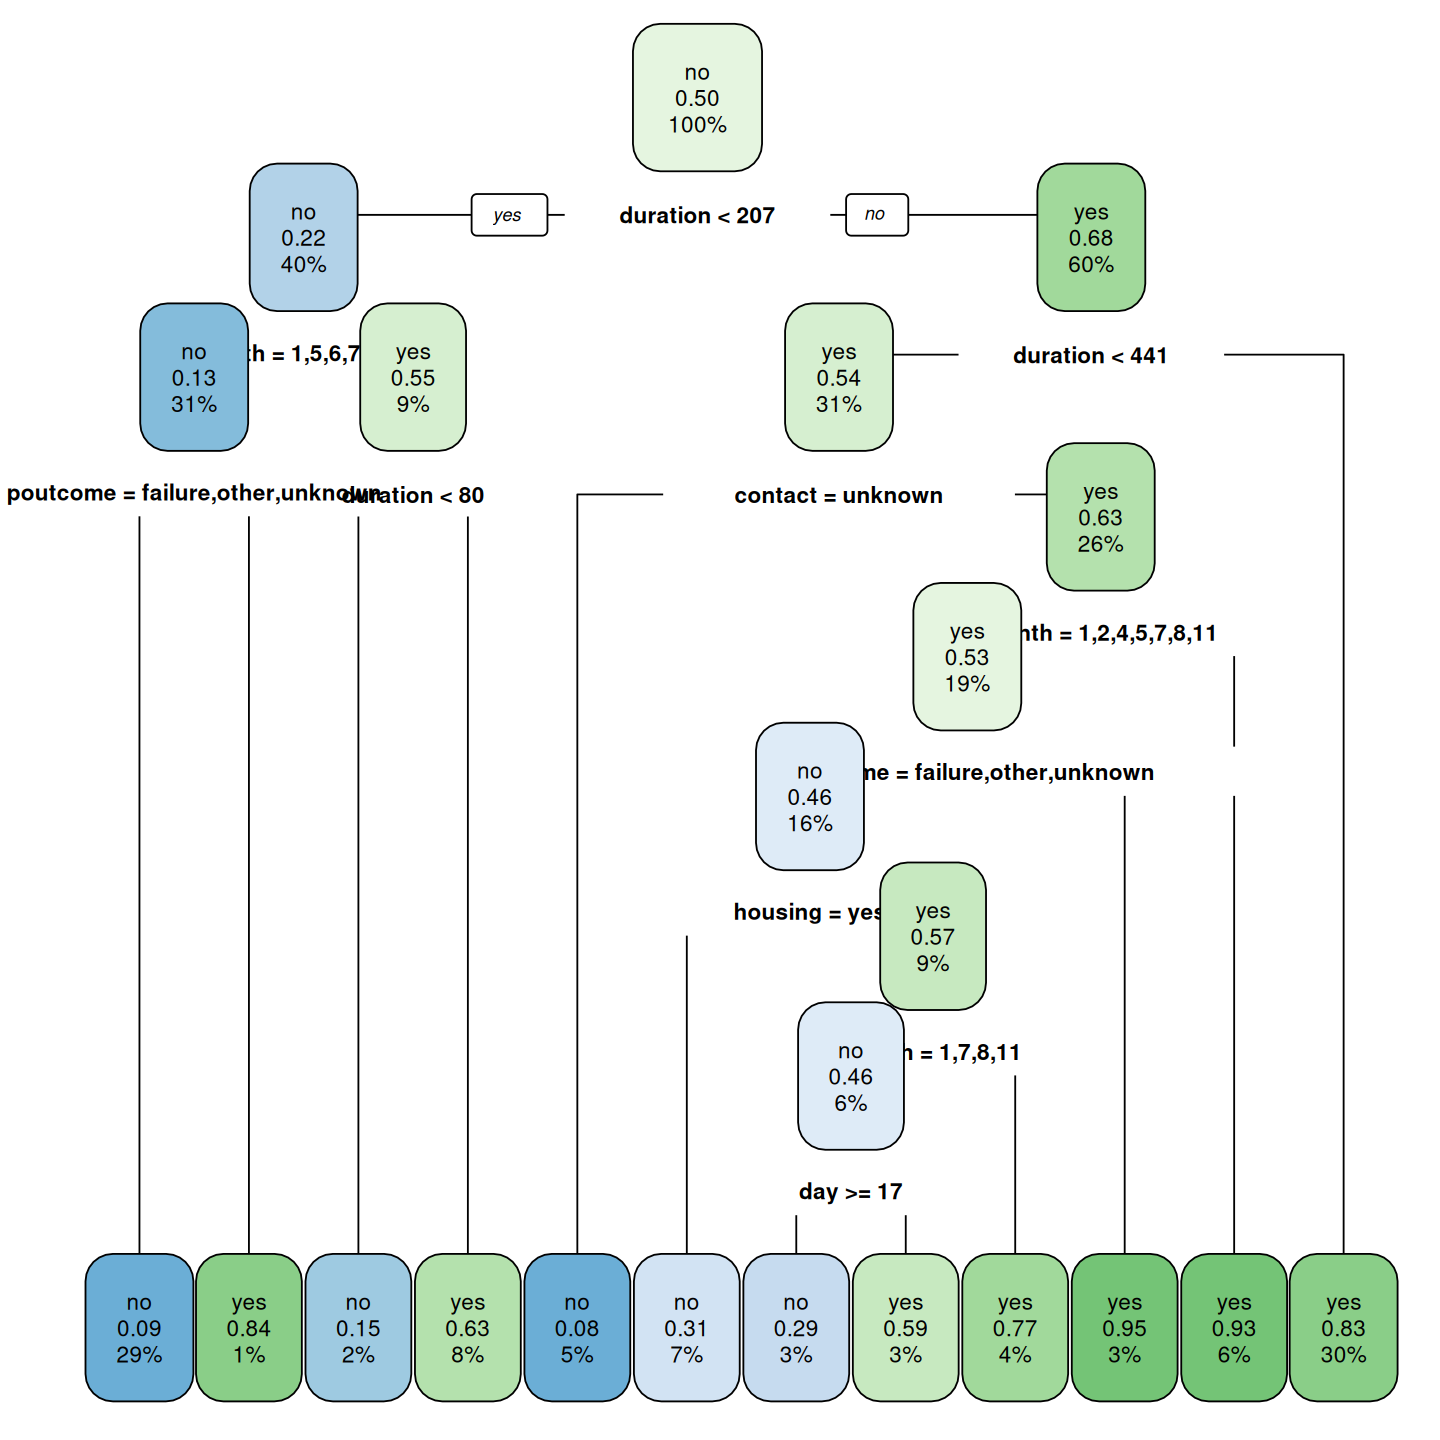

In [446]:
rpart.plot(modelo_peso, cex=1.1)

In [447]:
predito_peso <- predict(modelo_peso, bank_treino, type="class")

In [448]:
(matconf_peso <- confusionMatrix(predito_peso, bank_treino$contrata, positive="yes"))

Confusion Matrix and Statistics

          Reference
Prediction    no   yes
       no  21884   460
       yes  6099  3206
                                        
               Accuracy : 0.793         
                 95% CI : (0.788, 0.797)
    No Information Rate : 0.884         
    P-Value [Acc > NIR] : 1             
                                        
                  Kappa : 0.394         
                                        
 Mcnemar's Test P-Value : <2e-16        
                                        
            Sensitivity : 0.875         
            Specificity : 0.782         
         Pos Pred Value : 0.345         
         Neg Pred Value : 0.979         
             Prevalence : 0.116         
         Detection Rate : 0.101         
   Detection Prevalence : 0.294         
      Balanced Accuracy : 0.828         
                                        
       'Positive' Class : yes           
                                        

In [449]:
(accbal_peso <- matconf_peso$byClass["Balanced Accuracy"])

Balanced Accuracy 
            0.828

In [450]:
tabela <- as.data.frame(matconf_peso$table)
tabela$Reference <- factor(tabela$Reference, levels=rev(levels(tabela$Reference)))
tabela

Prediction,Reference,Freq
<fct>,<fct>,<int>
no,no,21884
yes,no,6099
no,yes,460
yes,yes,3206


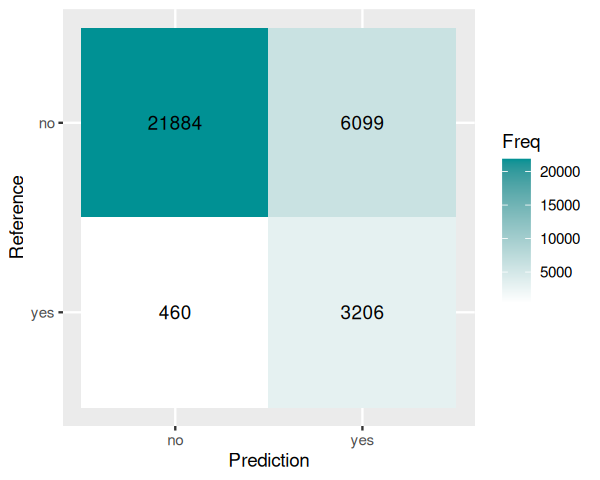

In [451]:
grafdim(5,4)
ggplot(tabela, aes(Prediction, Reference, fill=Freq)) +
        geom_tile() + geom_text(aes(label=Freq)) +
        scale_fill_gradient(low="white", high="#009194") +
        labs(x="Prediction", y="Reference")

Melhorou bastante a captura dos casos positivos, mas ainda há uma quantidade muito grande de falsos positivos que, para o caso em questão, é menos pior que falso negativo.

Para um exemplo com poda, veja [Modelo com poda](#Modelo-com-poda), do Caso 2.

In [452]:
printcp(modelo_peso)


Classification tree:
rpart(formula = contrata ~ ., data = bank_treino, weights = pesos, 
    method = "class", minsplit = 20, minbucket = 7, maxdepth = 30)

Variables actually used in tree construction:
[1] contact  day      duration housing  month    poutcome

Root node error: 3241/31649 = 0.1

n= 31649 

    CP nsplit rel error xerror xstd
1 0.44      0       1.0    1.0 0.01
2 0.04      1       0.6    0.6 0.01
3 0.02      3       0.5    0.5 0.01
4 0.02      6       0.4    0.4 0.01
5 0.01      9       0.4    0.4 0.01
6 0.01     11       0.3    0.4 0.01


Como regra, costuma-se podar uma árvore de decisão no CP da menor árvore que está dentro de um desvio padrão da árvore com o menor `xerror`. Neste exemplo, o menor xerror é 0,36841, com um desvio padrão de 0,0096282. Como 0,36841 + 0,0096292 = 0,3780392 que ainda é inferior ao nível anterior (0,38370), a poda é no nível 6 mesmo.

#### Validação 

Vamos analisar como o modelo com peso se comporta com os dados de validação.

In [453]:
predito_valida <- predict(modelo_peso, bank_valida, type="class")

In [454]:
(matconf_valida <- confusionMatrix(predito_valida, bank_valida$contrata, positive="yes"))

Confusion Matrix and Statistics

          Reference
Prediction   no  yes
       no  4579   98
       yes 1371  733
                                        
               Accuracy : 0.783         
                 95% CI : (0.773, 0.793)
    No Information Rate : 0.877         
    P-Value [Acc > NIR] : 1             
                                        
                  Kappa : 0.393         
                                        
 Mcnemar's Test P-Value : <2e-16        
                                        
            Sensitivity : 0.882         
            Specificity : 0.770         
         Pos Pred Value : 0.348         
         Neg Pred Value : 0.979         
             Prevalence : 0.123         
         Detection Rate : 0.108         
   Detection Prevalence : 0.310         
      Balanced Accuracy : 0.826         
                                        
       'Positive' Class : yes           
                                        

In [455]:
(accbal_valida <- matconf_valida$byClass["Balanced Accuracy"])

Balanced Accuracy 
            0.826

In [456]:
tabela <- as.data.frame(matconf_valida$table)
tabela$Reference <- factor(tabela$Reference, levels=rev(levels(tabela$Reference)))
tabela

Prediction,Reference,Freq
<fct>,<fct>,<int>
no,no,4579
yes,no,1371
no,yes,98
yes,yes,733


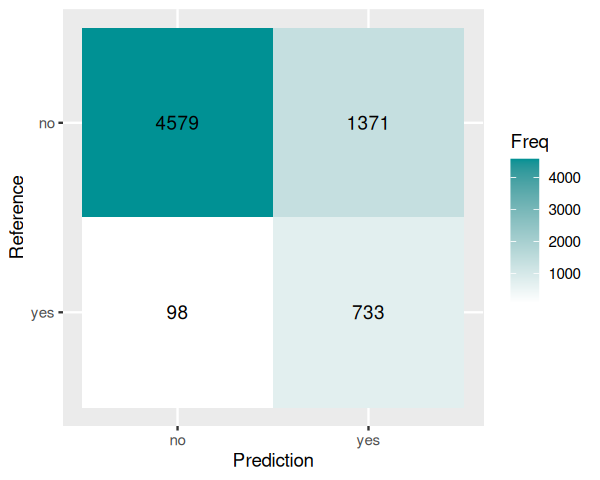

In [457]:
ggplot(tabela, aes(Prediction, Reference, fill=Freq)) +
        geom_tile() + geom_text(aes(label=Freq)) +
        scale_fill_gradient(low="white", high="#009194") +
        labs(x="Prediction", y="Reference")

O desempenho do modelo para os dados de validação foi similar àquele dos dados de treino, com acurácia balanceada de 0,826 (comparada à de 8,828 do conjunto de treino).

#### Teste

Vamos examinar como o modelo se comporta com o conjunto de teste.

In [458]:
predito_teste <- predict(modelo_peso, bank_teste, type="class")

In [459]:
(matconf_teste <- confusionMatrix(predito_teste, bank_teste$contrata, positive="yes"))

Confusion Matrix and Statistics

          Reference
Prediction   no  yes
       no  4636   91
       yes 1353  701
                                        
               Accuracy : 0.787         
                 95% CI : (0.777, 0.797)
    No Information Rate : 0.883         
    P-Value [Acc > NIR] : 1             
                                        
                  Kappa : 0.39          
                                        
 Mcnemar's Test P-Value : <2e-16        
                                        
            Sensitivity : 0.885         
            Specificity : 0.774         
         Pos Pred Value : 0.341         
         Neg Pred Value : 0.981         
             Prevalence : 0.117         
         Detection Rate : 0.103         
   Detection Prevalence : 0.303         
      Balanced Accuracy : 0.830         
                                        
       'Positive' Class : yes           
                                        

In [460]:
(accbal_teste <- matconf_teste$byClass["Balanced Accuracy"])

Balanced Accuracy 
             0.83

In [461]:
tabela <- as.data.frame(matconf_teste$table)
tabela$Reference <- factor(tabela$Reference, levels=rev(levels(tabela$Reference)))
tabela

Prediction,Reference,Freq
<fct>,<fct>,<int>
no,no,4636
yes,no,1353
no,yes,91
yes,yes,701


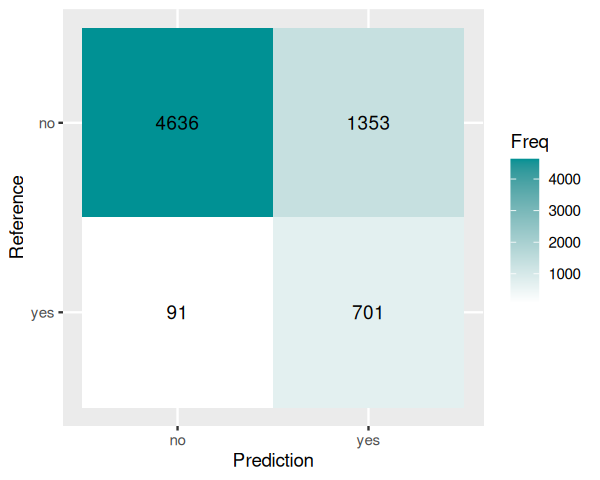

In [462]:
ggplot(tabela, aes(Prediction, Reference, fill=Freq)) +
        geom_tile() + geom_text(aes(label=Freq)) +
        scale_fill_gradient(low="white", high="#009194") +
        labs(x="Prediction", y="Reference")

O desempenho do modelo para os dados de teste foi similar àquele dos dados de treino e validação, com acurácia balanceada de 0,830 (comparada à de 8,828 do conjunto de treino e 0,826 do conjunto de validação). O modelo é razoavelmente bom e foi capaz de generalizar a predição mesmo para casos desconhecidos, não utilizados no treinamento.